# ETS Analisis Numerik: Kapal dengan Haluan Prisma Segitiga dan Buritan Elips

**Mata kuliah:** Analisis Numerik (Prodi Sains Data, FIK UPN "Veteran" Jawa Timur)  
**Ujian:** ETS TA 2026/2027, Senin 19 Oktober 2026 (open book, 120 menit)  
**Tiga digit terakhir NPM:** 028, sehingga `npm3 = 28` dan $h_{beban} = 200 - 28 = 172$ cm  
**Nama:** Oline Ola Fadhillah  
**NPM:** 25083010028

**Alur pengerjaan:** Langkah 0 mengidentifikasi data dari soal. Langkah 1 sampai 7 mengikuti nomor soal. Setiap langkah berisi Tujuan, Penjelasan, Data, Rumus, Kode Python, visualisasi, dan Interpretasi. Di akhir ada *Kesimpulan Akhir* (Diketahui, Ditanya, Penyelesaian, Jawaban) untuk ditulis ulang pada lembar jawaban.

**Dua versi jawaban.** Soal 5 menulis muatan = tiga digit terakhir NPM x 100 ton = 2800 ton. Dibaca apa adanya, kapal pasti tenggelam. Karena itu Langkah 5, 6, dan 7 dikerjakan dua kali:
- **Versi A (sesuai soal):** muatan 2800 ton, dikerjakan apa adanya. Ini jawaban utama.
- **Versi B (penyangkalan/revisi):** usulan koreksi satuan menjadi 28 x 100 **kg** = 2800 kg, lengkap dengan alasan logis, kode, visualisasi, dan interpretasi.

Langkah 1 sampai 4 tidak bergantung pada muatan, sehingga jawabannya satu.

**Cara menjalankan:** buka notebook ini (VS Code, Jupyter, atau Google Colab), pilih kernel Python, lalu klik *Run All*. Notebook tidak membutuhkan file lain.

> Jika library belum terpasang, jalankan `%pip install numpy scipy matplotlib` di sel baru, restart kernel, lalu jalankan ulang dari atas.

---
## Langkah 0: Identifikasi Data dari Soal

**Tujuan**  
Menentukan dimensi kapal dan data soal sebelum melakukan perhitungan.

**Penjelasan**  
Soal berupa gambar kapal dengan haluan berbentuk prisma segitiga, badan tengah berbentuk balok, dan buritan berbentuk elips $4x^2 + (y-2)^2 = 4$, beserta tujuh pertanyaan. Data dibaca dari gambar dan teks soal, lalu dimasukkan manual ke variabel Python.

**Data yang diidentifikasi dari gambar dan teks soal**

| Label pada gambar / soal | Arti | Nilai |
|---|---|---|
| 2 m (di atas bagian kiri) | panjang haluan (prisma segitiga) | 2 m |
| 6 m (di bawah alas datar) | panjang badan tengah | 6 m |
| 1 m (di atas bagian kanan) | panjang buritan = semi-sumbu horizontal elips | 1 m |
| 2 m (garis tegak tengah dan kanan) | tinggi lambung = semi-sumbu vertikal elips | 2 m |
| 3 m (garis putus-putus miring, kiri dan kanan) | lebar kapal | 3 m |
| 45° | sudut bidang miring haluan | 45° |
| $4x^2 + (y-2)^2 = 4$ | profil buritan, rasio sumbu 2:1 | $a = 1$ m, $b = 2$ m |
| massa jenis air | sesuai soal | 1 ton/m³ = 1000 kg/m³ |
| berat jenis baja | per luas pelat, termasuk dek atas | 160 kg/m² |
| muatan | tiga digit terakhir NPM x 100 ton | Versi A: 2800 ton; Versi B: 2800 kg |
| $h_{beban}$ | tinggi muatan di atas dek | 200 - 28 = 172 cm |

**Cara membaca gambar (asumsi)**
- Panjang total kapal = 2 + 6 + 1 = 9 m.
- Haluan: profil samping segitiga siku-siku dengan alas atas 2 m dan tinggi 2 m, konsisten dengan sudut 45° karena $\tan 45° = 2/2$.
- Buritan: $4x^2 + (y-2)^2 = 4 \iff \dfrac{x^2}{1^2} + \dfrac{(y-2)^2}{2^2} = 1$, yaitu elips berpusat di $(0, 2)$ dengan semi-sumbu 1 m (horizontal) dan 2 m (vertikal). Dipakai seperempat elips dari dasar ($y = 0$, $x = 0$) sampai dek ($y = 2$, $x = 1$).
- Lambung tertutup pelat baja di semua sisi termasuk dek atas. Garis putus-putus pada gambar adalah garis tersembunyi, bukan sekat.
- Muatan berdiri di atas dek (mulai ketinggian 2 m) dengan massa terdistribusi rata secara vertikal.

**Kode:** memasukkan data ke variabel dan memeriksa panjang total serta sudut haluan.

In [1]:
# Pemangkasan otomatis (bbox_inches="tight") pada tampilan inline bisa salah menghitung batas gambar 3D.
# Dimatikan supaya seluruh kanvas gambar tampil utuh.
try:
    get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except Exception:
    pass

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq

# ---- dimensi kapal dari gambar (meter) ----
p_haluan = 2.0    # panjang haluan (prisma segitiga)
p_tengah = 6.0    # panjang badan tengah
a_elips  = 1.0    # semi-sumbu horizontal elips buritan = panjang buritan
b_elips  = 2.0    # semi-sumbu vertikal elips buritan
lebar    = 3.0    # lebar kapal
tinggi   = 2.0    # tinggi lambung (lantai sampai dek)

# ---- data soal ----
rho        = 1000.0               # kg/m^3 (1 ton/m^3)
berat_baja = 160.0                # kg/m^2
npm3       = 28                   # tiga digit terakhir NPM = 028
h_beban    = (200 - npm3) / 100   # m, h_beban = 200 - NPM (cm)
g          = 9.81                 # m/s^2, hanya untuk konversi kgf ke N

# ---- muatan: versi A (sesuai soal) dan versi B (usulan koreksi satuan) ----
muatan_A = npm3 * 100 * 1000      # kg, 28 x 100 ton = 2.800.000 kg
muatan_B = npm3 * 100             # kg, 28 x 100 kg  = 2.800 kg

p_total = p_haluan + p_tengah + a_elips
sudut = np.degrees(np.arctan(tinggi / p_haluan))
print("Panjang total kapal =", p_total, "m")
print("Sudut haluan        =", sudut, "derajat")
print("h_beban             =", h_beban, "m")
print("Muatan versi A      =", muatan_A, "kg")
print("Muatan versi B      =", muatan_B, "kg")

Panjang total kapal = 9.0 m
Sudut haluan        = 45.0 derajat
h_beban             = 1.72 m
Muatan versi A      = 2800000 kg
Muatan versi B      = 2800 kg


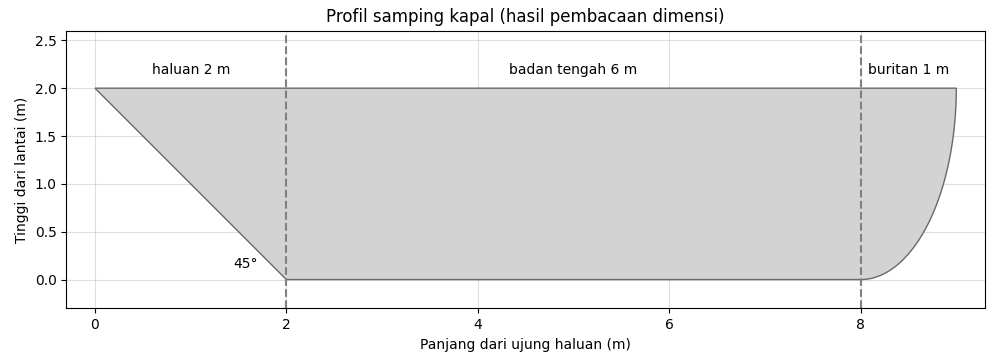

In [2]:
# ---------- profil samping kapal ----------
th = np.linspace(0, np.pi / 2, 60)                        # parameter elips buritan
x_elips = (p_haluan + p_tengah) + a_elips * np.sin(th)    # posisi memanjang
z_elips = tinggi - b_elips * np.cos(th)                   # tinggi dari lantai
x_profil = [0, p_haluan, p_haluan + p_tengah] + list(x_elips) + [0]
z_profil = [tinggi, 0, 0] + list(z_elips) + [tinggi]

# panjang profil kapal pada ketinggian z (dipakai di semua langkah)
def x_haluan(z):  return p_haluan - z                      # tepi depan pada ketinggian z
def x_buritan(z): return p_haluan + p_tengah + a_elips * np.sqrt(max(0.0, 1 - (z - tinggi)**2 / b_elips**2))

def profil_2d(ax, muatan=True, judul=""):
    ax.fill(x_profil, z_profil, color="lightgray", edgecolor="dimgray", zorder=2)
    if muatan:
        ax.fill([3.5, 6.5, 6.5, 3.5], [tinggi, tinggi, tinggi + h_beban, tinggi + h_beban],
                color="sandybrown", edgecolor="saddlebrown", zorder=2)
    ax.set_xlim(-0.3, 9.3)
    ax.set_ylim(-0.3, 4.0 if muatan else 2.6)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Panjang dari ujung haluan (m)")
    ax.set_ylabel("Tinggi dari lantai (m)")
    ax.set_title(judul)
    ax.grid(True, alpha=0.4)

fig, ax = plt.subplots(figsize=(10, 3.6))
profil_2d(ax, muatan=False, judul="Profil samping kapal (hasil pembacaan dimensi)")
ax.axvline(p_haluan, color="gray", linestyle="--")
ax.axvline(p_haluan + p_tengah, color="gray", linestyle="--")
ax.text(1.0, 2.15, "haluan 2 m", ha="center")
ax.text(5.0, 2.15, "badan tengah 6 m", ha="center")
ax.text(8.5, 2.15, "buritan 1 m", ha="center")
ax.annotate("45°", (1.45, 0.12), fontsize=10)
plt.tight_layout()
plt.show()

In [3]:
# ---------- fungsi bantu gambar 3D ----------
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# bidang-bidang lambung: nama -> daftar poligon (tiap poligon = daftar titik (x, y, z))
def bidang_lambung():
    b = {"dek": [], "alas": [], "miring": [], "samping": [], "lengkung": []}
    b["dek"].append([(0, 0, tinggi), (p_total, 0, tinggi), (p_total, lebar, tinggi), (0, lebar, tinggi)])
    b["alas"].append([(p_haluan, 0, 0), (p_haluan + p_tengah, 0, 0),
                      (p_haluan + p_tengah, lebar, 0), (p_haluan, lebar, 0)])
    b["miring"].append([(0, 0, tinggi), (0, lebar, tinggi), (p_haluan, lebar, 0), (p_haluan, 0, 0)])
    for y in (0, lebar):
        b["samping"].append([(xx, y, zz) for xx, zz in zip(x_profil, z_profil)])
    for i in range(len(th) - 1):
        b["lengkung"].append([(x_elips[i], 0, z_elips[i]), (x_elips[i+1], 0, z_elips[i+1]),
                              (x_elips[i+1], lebar, z_elips[i+1]), (x_elips[i], lebar, z_elips[i])])
    return b

def semua_bidang():
    return [p for daftar in bidang_lambung().values() for p in daftar]

# balok muatan di atas dek (panjang dan lebarnya ilustrasi, hanya tingginya yang dipakai)
def bidang_muatan(x0=3.5, x1=6.5, y0=0.5, y1=2.5):
    z0, z1 = tinggi, tinggi + h_beban
    return [[(x0,y0,z0),(x1,y0,z0),(x1,y1,z0),(x0,y1,z0)], [(x0,y0,z1),(x1,y0,z1),(x1,y1,z1),(x0,y1,z1)],
            [(x0,y0,z0),(x1,y0,z0),(x1,y0,z1),(x0,y0,z1)], [(x0,y1,z0),(x1,y1,z0),(x1,y1,z1),(x0,y1,z1)],
            [(x0,y0,z0),(x0,y1,z0),(x0,y1,z1),(x0,y0,z1)], [(x1,y0,z0),(x1,y1,z0),(x1,y1,z1),(x1,y0,z1)]]

def geser_z(bidang, dz):
    return [[(x, y, z + dz) for x, y, z in p] for p in bidang]

# memotong poligon dengan bidang datar: sumbu 0 = x, 2 = z; bawah=True mengambil bagian <= nilai
def potong(poligon, sumbu, nilai, bawah=True):
    s = 1 if bawah else -1
    hasil = []
    for i in range(len(poligon)):
        p, q = poligon[i], poligon[(i + 1) % len(poligon)]
        if s * (p[sumbu] - nilai) <= 0:
            hasil.append(p)
        if (p[sumbu] - nilai) * (q[sumbu] - nilai) < 0:
            t = (nilai - p[sumbu]) / (q[sumbu] - p[sumbu])
            hasil.append(tuple(p[k] + t * (q[k] - p[k]) for k in range(3)))
    return hasil

# irisan datar lambung pada ketinggian z (persegi panjang dari tepi haluan ke tepi buritan)
def irisan(z, dz=0):
    x0, x1 = x_haluan(z), x_buritan(z)
    return [[(x0, 0, z + dz), (x1, 0, z + dz), (x1, lebar, z + dz), (x0, lebar, z + dz)]]

def tambah(ax, bidang, warna, tepi="dimgray", alpha=0.95, urut=1, lw=0.3):
    bidang = [p for p in bidang if len(p) >= 3]
    if bidang:
        c = Poly3DCollection(bidang, facecolor=warna, edgecolor=tepi, linewidth=lw, alpha=alpha)
        c.set_zorder(urut)                   # urutan gambar diatur manual (computed_zorder dimatikan)
        try:
            ax.add_collection3d(c, autolim=False)   # batas sumbu tidak ikut berubah
        except TypeError:
            ax.add_collection3d(c)                  # matplotlib versi lama

# membuat sumbu 3D; posisi = [kiri, bawah, lebar, tinggi] dalam pecahan figure
def sumbu_3d(fig, posisi=(0.0, 0.0, 1.0, 0.92)):
    ax = fig.add_axes(posisi, projection="3d")
    ax.computed_zorder = False               # supaya muatan tidak tertutup lambung
    ax.set_autoscale_on(False)               # batas sumbu hanya diatur oleh fungsi rapikan
    return ax

# merapikan sumbu: tick dibuat jarang supaya angka tidak tumpang tindih, zoom < 1 supaya tidak terpotong
def rapikan(ax, zlim=(0, 4), zticks=(0, 2, 4), judul="", kecil=False, elev=22, azim=-58, zoom=None):
    ax.set_autoscale_on(False)
    ax.set_xlim(0, 9, auto=False); ax.set_ylim(0, 3, auto=False); ax.set_zlim(*zlim, auto=False)
    span = zlim[1] - zlim[0]
    ax.set_box_aspect((9, 3, span), zoom=zoom if zoom else (0.9 if kecil else 1.0))
    ax.set_xticks([0, 2, 4, 6, 8]); ax.set_yticks([0, 1.5, 3]); ax.set_zticks(list(zticks))
    ax.tick_params(labelsize=7 if kecil else 8, pad=1)
    if not kecil:
        ax.set_xlabel("Panjang (m)", labelpad=6)
        ax.set_ylabel("Lebar (m)", labelpad=2)
        ax.set_zlabel("Tinggi (m)", labelpad=0)
    ax.set_title(judul, fontsize=9 if kecil else 11, y=0.93 if kecil else 0.95)
    ax.view_init(elev=elev, azim=azim)

# menggambar kapal; dz = pergeseran kapal terhadap permukaan air (z = 0 adalah permukaan air)
def isi_kapal(ax, dz=0.0, air=False, muatan=True, alpha_lambung=0.95, alpha_muatan=0.95, air_depan=False):
    lambung = geser_z(semua_bidang(), dz)
    if air:
        tambah(ax, [potong(p, 2, 0, True) for p in lambung], "steelblue", "navy", alpha_lambung, 1)
        permukaan = [[(0, 0, 0), (9, 0, 0), (9, 3, 0), (0, 3, 0)]]
        tambah(ax, permukaan, "deepskyblue", "none", 0.3, 9 if air_depan else 2)
        tambah(ax, [potong(p, 2, 0, False) for p in lambung], "lightgray", "dimgray", alpha_lambung, 3)
        h = -dz                                  # kedalaman tenggelam
        if 0 < h < tinggi:                       # garis air pada lambung (sisi depan, haluan, buritan)
            x0, x1 = x_haluan(h), x_buritan(h)
            for xs, ys in [([x0, x1], [0, 0]), ([x0, x0], [0, lebar]), ([x1, x1], [0, lebar])]:
                ax.plot(xs, ys, [0, 0], color="blue", linewidth=1.8, zorder=4)
    else:
        tambah(ax, lambung, "lightgray", "dimgray", alpha_lambung, 1)
    if muatan:
        tambah(ax, geser_z(bidang_muatan(), dz), "sandybrown", "saddlebrown", alpha_muatan, 7, 0.6)

def keterangan(fig, baris, handles=None, lokasi="upper left"):
    h = list(handles or []) + [Patch(facecolor="none", edgecolor="none", label=t) for t in baris]
    fig.legend(handles=h, loc=lokasi, fontsize=8.5, frameon=True)

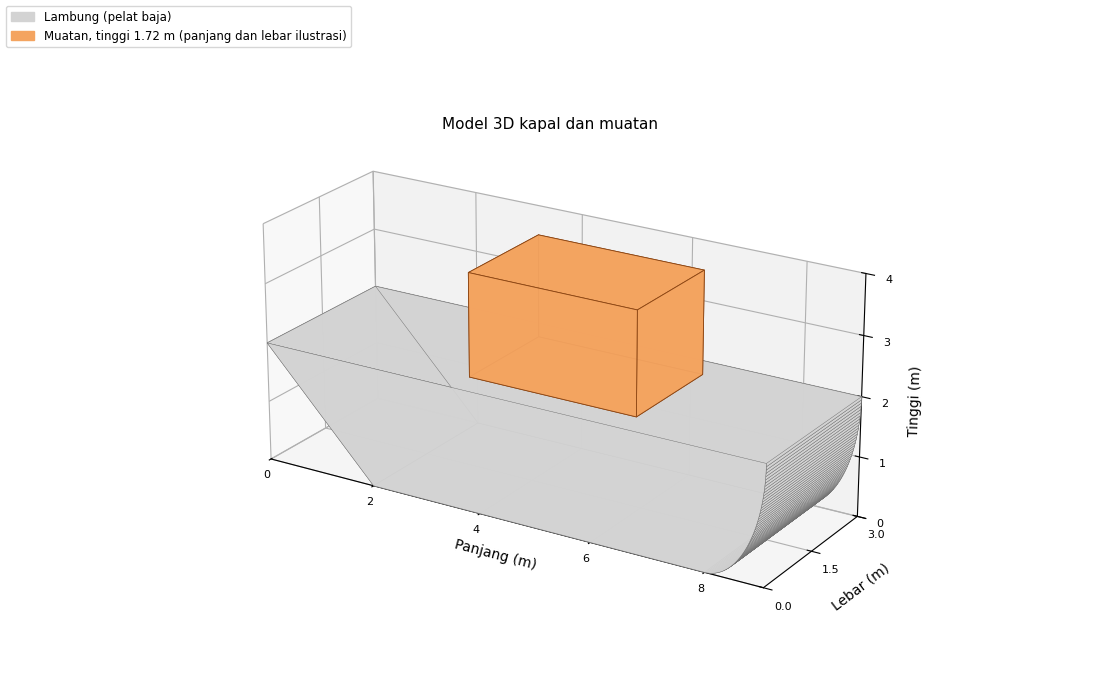

In [4]:
# model 3D kapal dan muatan (tanpa air)
fig = plt.figure(figsize=(11, 7))
ax = sumbu_3d(fig)
isi_kapal(ax, 0, air=False, muatan=True)
rapikan(ax, (0, 4), (0, 1, 2, 3, 4), "Model 3D kapal dan muatan")
keterangan(fig, [], [Patch(color="lightgray", label="Lambung (pelat baja)"),
                     Patch(color="sandybrown", label=f"Muatan, tinggi {h_beban} m (panjang dan lebar ilustrasi)")])
plt.show()

**Interpretasi**  
Panjang total kapal 9 m dan sudut haluan 45°, sesuai label pada gambar. Profil samping dan model 3D memperlihatkan haluan miring, alas datar 6 m, dan buritan melengkung seperempat elips seperti gambar soal. Balok muatan hanyalah ilustrasi: soal hanya memberi tingginya ($h_{beban} = 1.72$ m), dan hanya tinggi itu yang dipakai dalam perhitungan.

---
## Langkah 1: Volume Total Kapal dan Gaya Apung Maksimum

**Tujuan**  
Menghitung volume total kapal dan gaya apung maksimum.

**Penjelasan**  
Gaya apung maksimum terjadi ketika seluruh lambung terendam sampai dek. Lambung diiris horizontal pada ketinggian $z$ dari lantai. Karena lebarnya tetap 3 m, volume = lebar x integral panjang irisan $L(z)$. Panjang irisan terdiri atas tiga bagian:
- haluan: pada ketinggian $z$ panjangnya $z$ (kemiringan 45°),
- badan tengah: tetap 6 m,
- buritan: dari persamaan elips, $\sqrt{1 - (z-2)^2/4}$.

**Data**  
$p_{haluan} = 2$ m, $p_{tengah} = 6$ m, $a = 1$ m, $b = 2$ m, lebar $= 3$ m, tinggi $= 2$ m, $\rho = 1000$ kg/m³.

**Rumus**
$$L(z) = z + 6 + \sqrt{1 - \frac{(z-2)^2}{4}}$$
$$V(x) = \text{lebar} \int_0^x L(z)\,dz \qquad V_{total} = V(2) \qquad F_b = \rho\, V$$

Pemeriksaan dengan rumus bangun ruang: $V_{haluan} = \tfrac12 \cdot 2 \cdot 2 \cdot 3$, $V_{tengah} = 6 \cdot 2 \cdot 3$, $V_{buritan} = \tfrac14 \pi a b \cdot 3$ (luas seperempat elips $= \pi ab/4$). Integral dihitung numerik dengan `scipy.integrate.quad`.

In [5]:
# panjang lambung pada ketinggian z dari lantai
def L(z):
    haluan  = z
    tengah  = p_tengah
    buritan = a_elips * np.sqrt(max(0.0, 1 - (z - tinggi)**2 / b_elips**2))
    return haluan + tengah + buritan

# volume terendam sedalam x
def volume_terendam(x):
    luas, _ = quad(L, 0, x)
    return lebar * luas

V_total = volume_terendam(tinggi)

V_haluan  = 0.5 * p_haluan * tinggi * lebar
V_tengah  = p_tengah * tinggi * lebar
V_buritan = 0.25 * np.pi * a_elips * b_elips * lebar
V_cek = V_haluan + V_tengah + V_buritan

Fb_max = rho * V_total          # kgf

print("V haluan          =", round(V_haluan, 4), "m^3")
print("V badan tengah    =", round(V_tengah, 4), "m^3")
print("V buritan         =", round(V_buritan, 4), "m^3")
print("V total (rumus)   =", round(V_cek, 4), "m^3")
print("V total (numerik) =", round(V_total, 4), "m^3")
print("Selisih           =", abs(V_total - V_cek))
print("Gaya apung maksimum =", round(Fb_max, 2), "kgf =", round(Fb_max / 1000, 4), "ton")
print("                    =", round(Fb_max * g, 2), "N")

V haluan          = 6.0 m^3
V badan tengah    = 36.0 m^3
V buritan         = 4.7124 m^3
V total (rumus)   = 46.7124 m^3
V total (numerik) = 46.7124 m^3
Selisih           = 2.1316282072803006e-14
Gaya apung maksimum = 46712.39 kgf = 46.7124 ton
                    = 458248.54 N


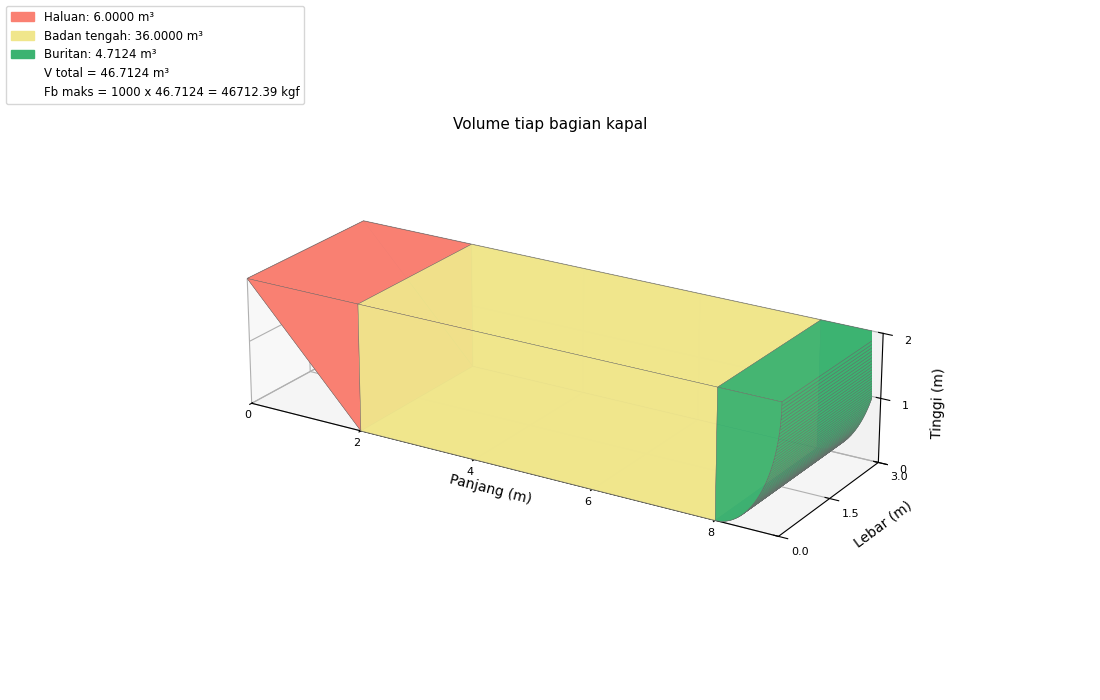

In [6]:
# 3D: lambung dibagi tiga bagian sesuai perhitungan volume
sem = semua_bidang()
haluan_3d  = [potong(p, 0, p_haluan, True) for p in sem]
tengah_3d  = [potong(potong(p, 0, p_haluan, False), 0, p_haluan + p_tengah, True) for p in sem]
buritan_3d = [potong(p, 0, p_haluan + p_tengah, False) for p in sem]

fig = plt.figure(figsize=(11, 7))
ax = sumbu_3d(fig)
tambah(ax, haluan_3d, "salmon", urut=1)
tambah(ax, tengah_3d, "khaki", urut=2)
tambah(ax, buritan_3d, "mediumseagreen", urut=3)
rapikan(ax, (0, 2), (0, 1, 2), "Volume tiap bagian kapal")
keterangan(fig, [f"V total = {V_total:.4f} m³", f"Fb maks = 1000 x {V_total:.4f} = {Fb_max:.2f} kgf"],
           [Patch(color="salmon", label=f"Haluan: {V_haluan:.4f} m³"),
            Patch(color="khaki", label=f"Badan tengah: {V_tengah:.4f} m³"),
            Patch(color="mediumseagreen", label=f"Buritan: {V_buritan:.4f} m³")])
plt.show()

**Interpretasi**
- **Hasil:** volume total $V = 6 + 36 + 4.7124 = \mathbf{46.7124}$ m³. Gaya apung maksimum $F_b = 1000 \times 46.7124 = \mathbf{46712.39}$ kgf (sekitar 46.71 ton atau 458248.54 N).
- **Artinya:** gaya apung maksimum adalah gaya angkat terbesar dari air, yaitu saat seluruh lambung terendam. Kapal beserta isinya paling berat 46.71 ton agar masih bisa mengapung.
- **Pemeriksaan:** integral numerik dan rumus bangun ruang memberi hasil yang sama, sehingga fungsi $L(z)$ sudah benar.
- **Dari gambar 3D:** tiga warna menunjukkan tiga bagian yang volumenya dijumlahkan. Badan tengah paling besar (36 dari 46.71 m³).
- **Satuan:** volume dalam m³, gaya dalam kgf dan N.

---
## Langkah 2: Kurva Ketinggian Tenggelam (x) vs Gaya Apung (y)

**Tujuan**  
Menggambar kurva gaya apung $F_b$ terhadap ketinggian tenggelam $x$.

**Penjelasan**  
$x$ adalah tinggi bagian lambung di bawah permukaan air, diukur dari lantai kapal ($0 \le x \le 2$ m). Untuk setiap $x$ dihitung $V(x)$ dengan fungsi Langkah 1, lalu dikali $\rho$. Dipakai 81 titik dengan jarak 0.025 m.

**Data**  
$0 \le x \le 2$ m, $\rho = 1000$ kg/m³, fungsi $L(z)$ dan $V(x)$ dari Langkah 1.

**Rumus**
$$V(x) = \underbrace{1.5x^2}_{\text{haluan}} + \underbrace{18x}_{\text{tengah}} + \underbrace{3\int_0^x \sqrt{1 - \tfrac{(z-2)^2}{4}}\,dz}_{\text{buritan (numerik)}} \qquad F_b(x) = \rho\,V(x) \qquad \frac{dF_b}{dx} = \rho\,\text{lebar}\,L(x)$$

In [7]:
x = np.linspace(0, tinggi, 81)
V_x = np.array([volume_terendam(xi) for xi in x])
Fb_x = rho * V_x

print(f"{'x (m)':>6s} {'1.5x^2':>8s} {'18x':>6s} {'V_buritan':>10s} {'V(x)':>9s} {'Fb (kgf)':>10s}")
for xi in [0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]:
    v = volume_terendam(xi)
    vb = v - 1.5 * xi**2 - 18 * xi
    print(f"{xi:6.2f} {1.5*xi**2:8.4f} {18*xi:6.1f} {vb:10.4f} {v:9.4f} {rho*v:10.2f}")

 x (m)   1.5x^2    18x  V_buritan      V(x)   Fb (kgf)
  0.00   0.0000    0.0     0.0000    0.0000       0.00
  0.25   0.0938    4.5     0.2453    4.8390    4839.01
  0.50   0.3750    9.0     0.6800   10.0550   10054.97
  0.75   0.8438   13.5     1.2233   15.5671   15567.07
  1.00   1.5000   18.0     1.8426   21.3426   21342.55
  1.25   2.3438   22.5     2.5163   27.3600   27360.05
  1.50   3.3750   27.0     3.2282   33.6032   33603.16
  1.75   4.5938   31.5     3.9643   40.0581   40058.10
  2.00   6.0000   36.0     4.7124   46.7124   46712.39


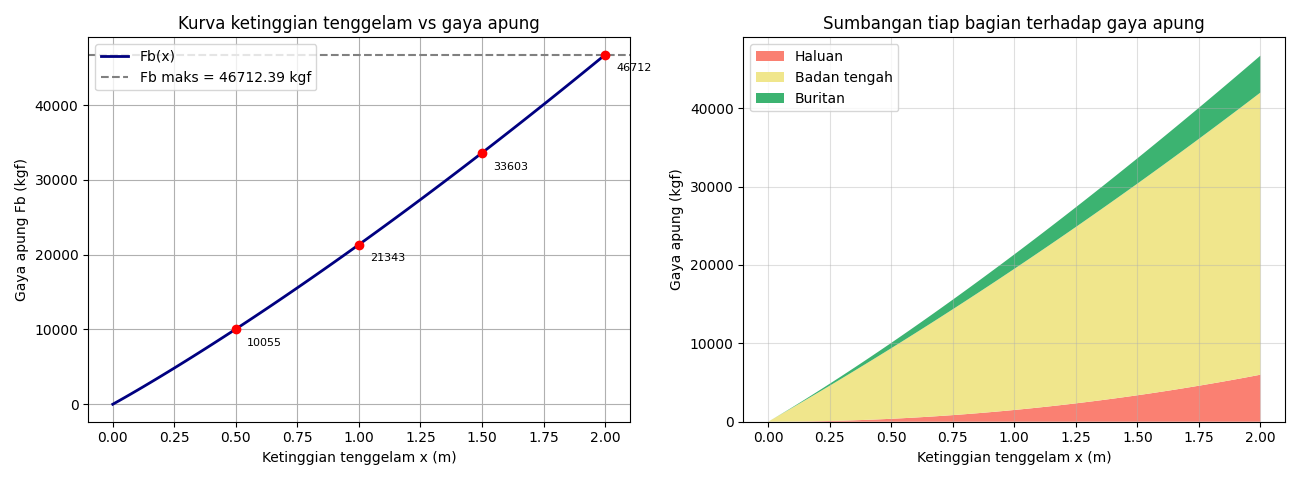

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
titik = [0.5, 1.0, 1.5, 2.0]
axs[0].plot(x, Fb_x, color="navy", linewidth=2, label="Fb(x)")
axs[0].scatter(titik, [rho * volume_terendam(v) for v in titik], color="red", zorder=3)
for v in titik:
    axs[0].annotate(f"{rho*volume_terendam(v):.0f}", (v, rho * volume_terendam(v)),
                    textcoords="offset points", xytext=(8, -12), fontsize=8)
axs[0].axhline(Fb_max, color="gray", linestyle="--", label=f"Fb maks = {Fb_max:.2f} kgf")
axs[0].set_xlabel("Ketinggian tenggelam x (m)"); axs[0].set_ylabel("Gaya apung Fb (kgf)")
axs[0].set_title("Kurva ketinggian tenggelam vs gaya apung")
axs[0].legend(loc="upper left"); axs[0].grid(True)

# komposisi gaya apung per bagian kapal
Fh = rho * 1.5 * x**2
Ft = rho * 18 * x
Fbur = Fb_x - Fh - Ft
axs[1].stackplot(x, Fh, Ft, Fbur, labels=["Haluan", "Badan tengah", "Buritan"],
                 colors=["salmon", "khaki", "mediumseagreen"])
axs[1].set_xlabel("Ketinggian tenggelam x (m)"); axs[1].set_ylabel("Gaya apung (kgf)")
axs[1].set_title("Sumbangan tiap bagian terhadap gaya apung")
axs[1].legend(loc="upper left"); axs[1].grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

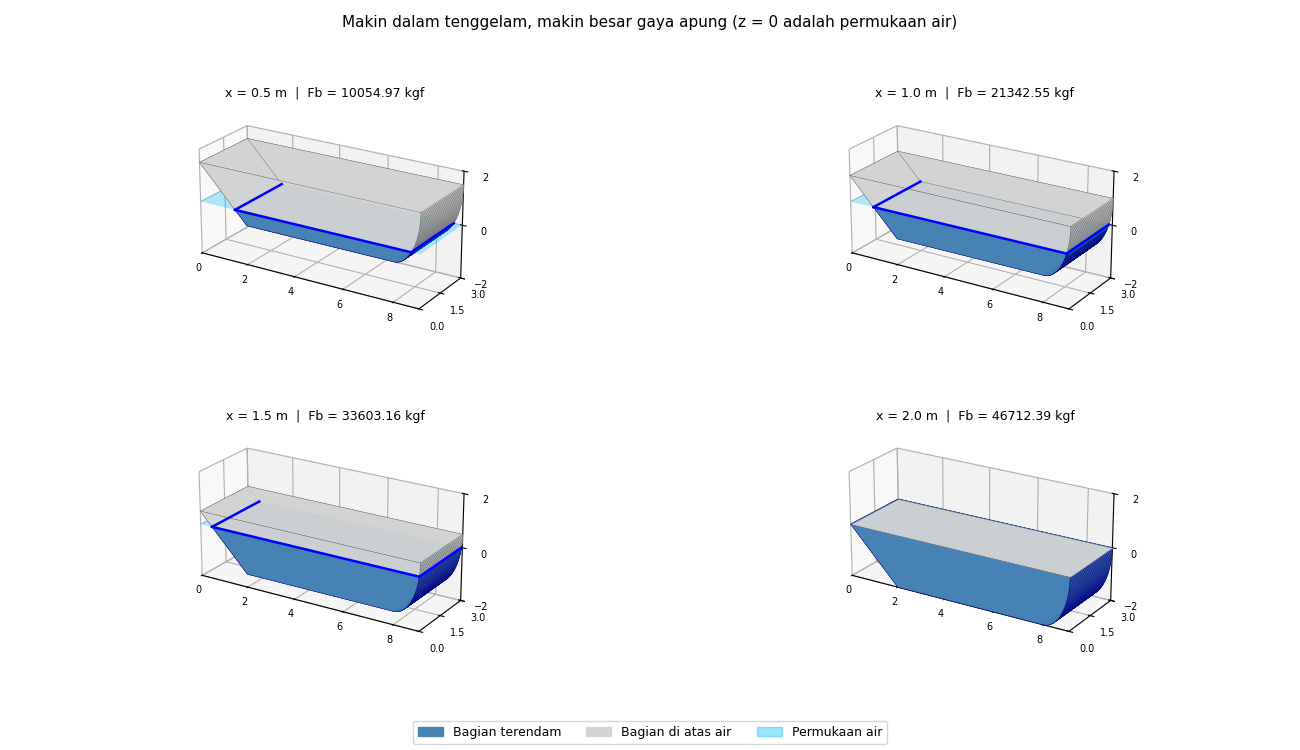

In [9]:
# 3D: kapal pada empat kedalaman tenggelam (bagian biru = terendam)
fig = plt.figure(figsize=(13, 7.5))
posisi = [(0.0, 0.50, 0.5, 0.42), (0.5, 0.50, 0.5, 0.42), (0.0, 0.07, 0.5, 0.42), (0.5, 0.07, 0.5, 0.42)]
for xi, pos in zip(titik, posisi):
    ax = sumbu_3d(fig, pos)
    isi_kapal(ax, -xi, air=True, muatan=False)
    rapikan(ax, (-2, 2), (-2, 0, 2), f"x = {xi} m  |  Fb = {rho * volume_terendam(xi):.2f} kgf", kecil=True)
fig.suptitle("Makin dalam tenggelam, makin besar gaya apung (z = 0 adalah permukaan air)", fontsize=11)
fig.legend(handles=[Patch(color="steelblue", label="Bagian terendam"),
                    Patch(color="lightgray", label="Bagian di atas air"),
                    Patch(color="deepskyblue", alpha=0.4, label="Permukaan air")],
           loc="lower center", ncol=3, fontsize=9)
plt.show()

**Interpretasi**
- **Hasil:** $F_b$ naik dari 0 kgf menjadi 10054.97; 21342.55; 33603.16; dan 46712.39 kgf pada $x = 0.5$; 1.0; 1.5; dan 2.0 m.
- **Artinya:** makin dalam kapal tenggelam, makin banyak air yang dipindahkan, sehingga gaya apung makin besar. Kurva makin curam ke atas karena haluan dan buritan melebar ke atas. Kemiringannya $3000\,L(x)$: 18000 kgf/m di lantai ($L = 6$ m) dan 27000 kgf/m di dek ($L = 9$ m).
- **Dari grafik komposisi:** badan tengah menyumbang bagian terbesar dan naik linear, sedangkan haluan dan buritan makin besar sumbangannya di bagian atas.
- **Dari gambar 3D:** bagian biru (terendam) makin banyak dari $x = 0.5$ sampai $x = 2$ m.
- **Satuan:** $x$ dalam m, $F_b$ dalam kgf.

---
## Langkah 3: Ketinggian Center of Buoyancy dari Lantai Kapal

**Tujuan**  
Menentukan tinggi center of buoyancy (CB) dari lantai kapal dengan ketelitian cm.

**Penjelasan**  
Center of buoyancy adalah titik berat volume air yang dipindahkan. Karena lebar kapal tetap, cukup dihitung titik berat profil samping yang terendam. Soal tidak menyebut kondisinya, sehingga jawaban utama memakai kondisi terendam penuh ($x = 2$ m, kondisi gaya apung maksimum pada Soal 1). Nilai CB pada kedalaman Soal 5 ditambahkan di Langkah 5.

**Data**  
Fungsi $L(z)$ dari Langkah 1, $x = 2$ m.

**Rumus**
$$z_B(x) = \frac{\int_0^x z\,L(z)\,dz}{\int_0^x L(z)\,dz}$$
Pemeriksaan dengan titik berat tiap bagian profil, $\bar z = \dfrac{\sum A_i z_i}{\sum A_i}$:
- segitiga haluan (titik sudut di $z$ = 2, 2, 0): $A_1 = 2$ m², $z_1 = (2 + 2 + 0)/3$
- persegi panjang tengah: $A_2 = 12$ m², $z_2 = 1$
- seperempat elips buritan: $A_3 = \pi ab/4 = \pi/2$ m², $z_3 = 2 - \dfrac{4b}{3\pi}$

In [10]:
def tinggi_cb(x):
    momen, _ = quad(lambda z: z * L(z), 0, x)
    luas, _  = quad(L, 0, x)
    return momen / luas

zB_penuh = tinggi_cb(tinggi)

A1, z1 = 0.5 * p_haluan * tinggi, (tinggi + tinggi + 0) / 3
A2, z2 = p_tengah * tinggi, tinggi / 2
A3, z3 = 0.25 * np.pi * a_elips * b_elips, tinggi - 4 * b_elips / (3 * np.pi)
zB_cek = (A1 * z1 + A2 * z2 + A3 * z3) / (A1 + A2 + A3)

print(f"{'bagian':10s} {'A (m^2)':>8s} {'z (m)':>8s} {'A*z':>9s}")
for n, A, z in [("haluan", A1, z1), ("tengah", A2, z2), ("buritan", A3, z3)]:
    print(f"{n:10s} {A:8.4f} {z:8.4f} {A*z:9.4f}")
print(f"{'jumlah':10s} {A1+A2+A3:8.4f} {'':8s} {A1*z1+A2*z2+A3*z3:9.4f}")
print()
print("zB penuh (integral numerik)  =", round(zB_penuh, 4), "m")
print("zB penuh (gabungan bagian)   =", round(zB_cek, 4), "m")
print("zB penuh dibulatkan          =", round(zB_penuh * 100), "cm")

bagian      A (m^2)    z (m)       A*z
haluan       2.0000   1.3333    2.6667
tengah      12.0000   1.0000   12.0000
buritan      1.5708   1.1512    1.8083
jumlah      15.5708            16.4749

zB penuh (integral numerik)  = 1.0581 m
zB penuh (gabungan bagian)   = 1.0581 m
zB penuh dibulatkan          = 106 cm


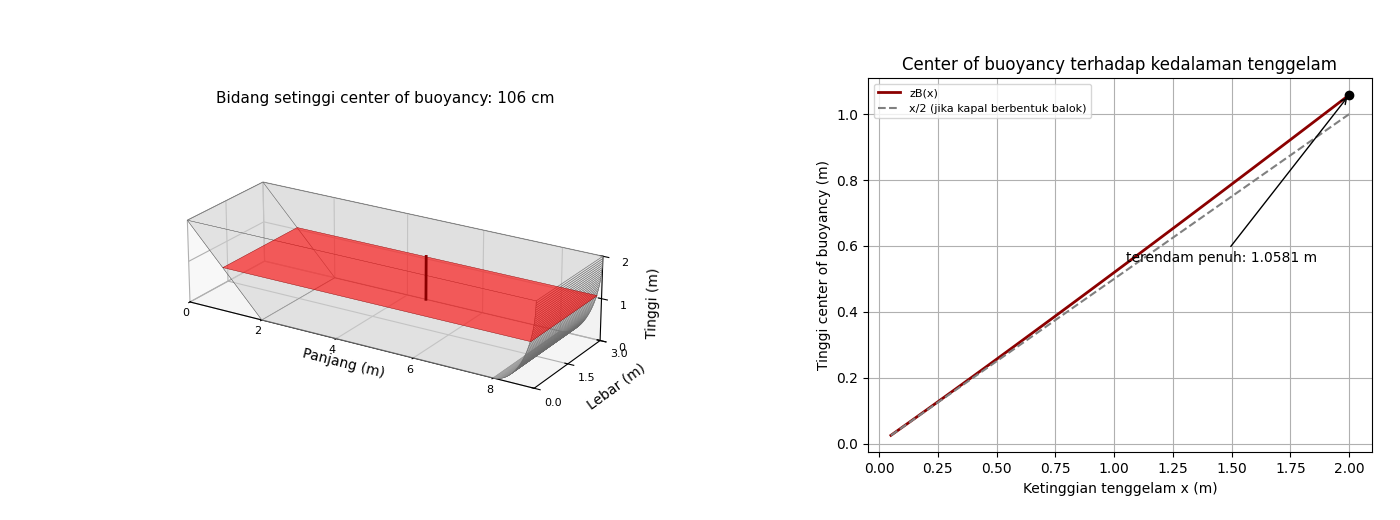

In [11]:
fig = plt.figure(figsize=(14, 5.2))
# kiri: 3D dengan bidang setinggi zB
ax = sumbu_3d(fig, (0.0, 0.0, 0.55, 0.9))
tambah(ax, semua_bidang(), "lightgray", "dimgray", 0.35, 1)
tambah(ax, irisan(zB_penuh), "red", "darkred", 0.6, 2)
ax.plot([4.5, 4.5], [lebar, lebar], [0, zB_penuh], color="darkred", linewidth=2, zorder=3)
rapikan(ax, (0, 2), (0, 1, 2), f"Bidang setinggi center of buoyancy: {zB_penuh*100:.0f} cm", zoom=0.9)
# kanan: zB terhadap kedalaman tenggelam
ax2 = fig.add_axes((0.62, 0.13, 0.36, 0.72))
x_cb = np.linspace(0.05, tinggi, 40)
ax2.plot(x_cb, [tinggi_cb(v) for v in x_cb], color="darkred", linewidth=2, label="zB(x)")
ax2.plot(x_cb, x_cb / 2, color="gray", linestyle="--", label="x/2 (jika kapal berbentuk balok)")
ax2.scatter([tinggi], [zB_penuh], color="black", zorder=3)
ax2.annotate(f"terendam penuh: {zB_penuh:.4f} m", (tinggi, zB_penuh), xytext=(1.05, 0.55), arrowprops=dict(arrowstyle="->"))
ax2.set_xlabel("Ketinggian tenggelam x (m)"); ax2.set_ylabel("Tinggi center of buoyancy (m)")
ax2.set_title("Center of buoyancy terhadap kedalaman tenggelam")
ax2.legend(loc="upper left", fontsize=8); ax2.grid(True)
plt.show()

**Interpretasi**
- **Hasil:** $z_B = 1.0581$ m, dibulatkan **1.06 m = 106 cm** dari lantai kapal. Cara integral numerik dan cara gabungan titik berat bagian memberi hasil yang sama.
- **Artinya:** CB berada sedikit di atas setengah tinggi lambung (1 m) karena haluan (titik berat 1.33 m) dan buritan (1.15 m) lebih lebar di bagian atas.
- **Dari grafik:** $z_B(x)$ selalu sedikit di atas $x/2$, karena badan kapal melebar ke atas. Bidang merah pada gambar 3D menunjukkan ketinggian CB saat terendam penuh.
- **Satuan:** meter (cm).

---
## Langkah 4: Massa Total Kapal (Pelat Baja)

**Tujuan**  
Menghitung massa kapal kosong dari pelat baja, termasuk dek atas.

**Penjelasan**  
Massa baja = berat jenis baja per luas x luas seluruh pelat. Pelat menutup permukaan luar lambung: dek atas, alas datar, bidang miring haluan, dua dinding samping, dan bidang lengkung buritan. Haluan dan buritan tidak punya alas sendiri karena ujung bawahnya langsung bertemu alas datar.

Bagian yang memerlukan metode numerik adalah **panjang busur seperempat elips**. Berbeda dengan lingkaran, panjang busur elips tidak punya rumus tertutup (integral eliptik), sehingga dihitung dengan integral numerik memakai parameter $x = a\sin\theta$, $z = 2 - b\cos\theta$, $0 \le \theta \le \pi/2$.

**Data**  
Berat jenis baja $= 160$ kg/m², dimensi kapal dari Langkah 0.

**Rumus**
- Dek atas: $A_{dek} = (2 + 6 + 1) \times 3$
- Alas datar: $A_{alas} = 6 \times 3$
- Bidang miring haluan: $A_{miring} = \sqrt{2^2 + 2^2} \times 3$
- Dua dinding samping: $A_{sisi} = 2\int_0^2 L(z)\,dz$
- Bidang lengkung buritan: $A_{lengkung} = s \times 3$, dengan $s = \displaystyle\int_0^{\pi/2}\sqrt{a^2\cos^2\theta + b^2\sin^2\theta}\,d\theta$

$$A_{total} = A_{dek} + A_{alas} + A_{miring} + A_{sisi} + A_{lengkung} \qquad M_{kapal} = 160 \times A_{total}$$

Panjang busur diperiksa dengan pendekatan Ramanujan untuk keliling elips, $K \approx \pi\left[3(a+b) - \sqrt{(3a+b)(a+3b)}\right]$, dibagi 4.

In [12]:
ds = lambda t: np.sqrt((a_elips * np.cos(t))**2 + (b_elips * np.sin(t))**2)
s_busur, _ = quad(ds, 0, np.pi / 2)
s_ramanujan = np.pi * (3 * (a_elips + b_elips) - np.sqrt((3 * a_elips + b_elips) * (a_elips + 3 * b_elips))) / 4

A_dek      = p_total * lebar
A_alas     = p_tengah * lebar
A_miring   = np.sqrt(p_haluan**2 + tinggi**2) * lebar
A_sisi     = 2 * quad(L, 0, tinggi)[0]
A_lengkung = s_busur * lebar
A_total = A_dek + A_alas + A_miring + A_sisi + A_lengkung
M_kapal = berat_baja * A_total

print("Panjang busur elips (numerik)   =", round(s_busur, 6), "m")
print("Panjang busur elips (Ramanujan) =", round(s_ramanujan, 6), "m")
print()
print(f"{'Pelat':26s} {'Luas (m^2)':>11s} {'Massa (kg)':>11s}")
for nama, A in [("Dek atas", A_dek), ("Alas datar", A_alas), ("Bidang miring haluan", A_miring),
                ("Dua dinding samping", A_sisi), ("Bidang lengkung buritan", A_lengkung), ("TOTAL", A_total)]:
    print(f"{nama:26s} {A:11.4f} {berat_baja*A:11.2f}")
print()
print("Massa total kapal =", round(M_kapal, 2), "kg =", round(M_kapal / 1000, 4), "ton")
print("Sisa daya angkut  =", round(Fb_max - M_kapal, 2), "kg")

Panjang busur elips (numerik)   = 2.422112 m
Panjang busur elips (Ramanujan) = 2.422105 m

Pelat                       Luas (m^2)  Massa (kg)
Dek atas                       27.0000     4320.00
Alas datar                     18.0000     2880.00
Bidang miring haluan            8.4853     1357.65
Dua dinding samping            31.1416     4982.65
Bidang lengkung buritan         7.2663     1162.61
TOTAL                          91.8932    14702.91

Massa total kapal = 14702.91 kg = 14.7029 ton
Sisa daya angkut  = 32009.48 kg


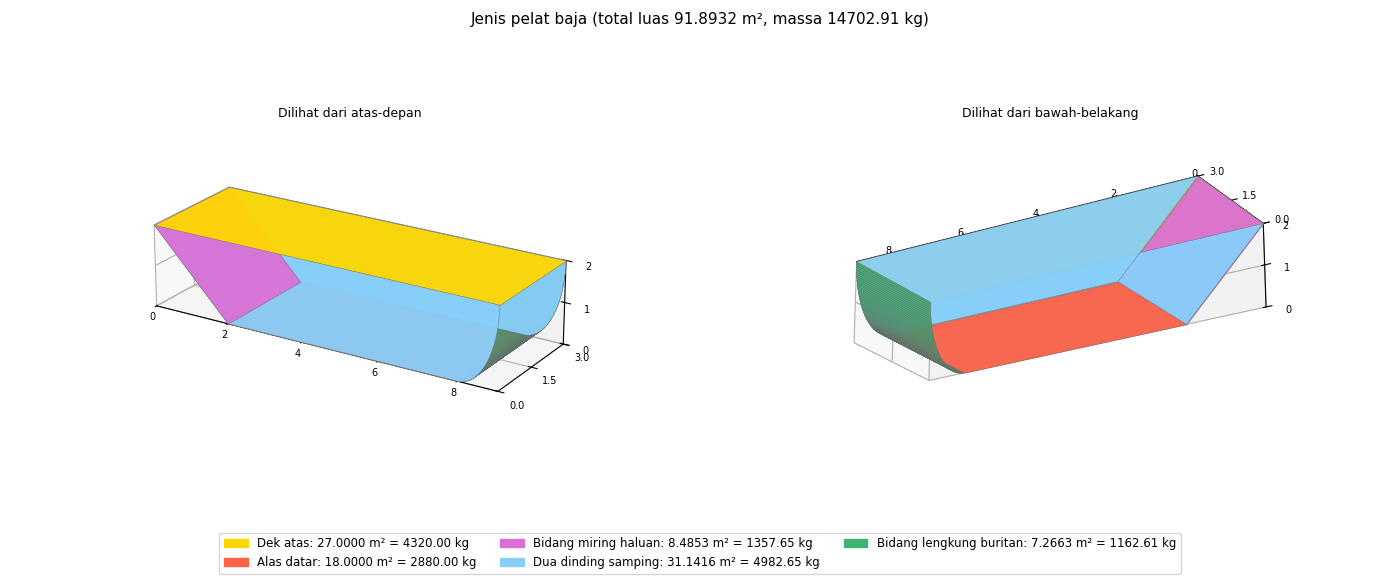

In [13]:
warna = {"dek": "gold", "alas": "tomato", "miring": "orchid", "samping": "lightskyblue", "lengkung": "mediumseagreen"}
luas  = {"dek": A_dek, "alas": A_alas, "miring": A_miring, "samping": A_sisi, "lengkung": A_lengkung}
nama  = {"dek": "Dek atas", "alas": "Alas datar", "miring": "Bidang miring haluan",
         "samping": "Dua dinding samping", "lengkung": "Bidang lengkung buritan"}
# urutan gambar per sudut pandang: bidang paling belakang digambar dulu
tampilan = [(22, -58, "Dilihat dari atas-depan", ["alas", "lengkung", "samping", "miring", "dek"]),
            (-22, 122, "Dilihat dari bawah-belakang", ["dek", "miring", "samping", "alas", "lengkung"])]
bid = bidang_lambung()
fig = plt.figure(figsize=(14, 5.8))
for k, (el, az, judul, urutan) in enumerate(tampilan):
    ax = sumbu_3d(fig, (0.5 * k, 0.1, 0.5, 0.8))
    for n, kunci in enumerate(urutan):
        tambah(ax, bid[kunci], warna[kunci], "dimgray", 0.95, n + 1)
    rapikan(ax, (0, 2), (0, 1, 2), judul, kecil=True, elev=el, azim=az)
fig.suptitle(f"Jenis pelat baja (total luas {A_total:.4f} m², massa {M_kapal:.2f} kg)", fontsize=11)
fig.legend(handles=[Patch(color=warna[k], label=f"{nama[k]}: {luas[k]:.4f} m² = {berat_baja*luas[k]:.2f} kg") for k in warna],
           loc="lower center", ncol=3, fontsize=8.5)
plt.show()

**Interpretasi**
- **Hasil:** panjang busur seperempat elips $s = 2.4221$ m (pendekatan Ramanujan juga 2.4221 m). Luas pelat total $A = 91.8932$ m², sehingga massa kapal kosong $M = 160 \times 91.8932 = \mathbf{14702.91}$ kg (sekitar 14.70 ton).
- **Artinya:** kapal kosong memakai 31.5% dari gaya apung maksimum (46712.39 kgf). Sisa daya angkut untuk muatan adalah $46712.39 - 14702.91 = 32009.48$ kg (sekitar 32.01 ton).
- **Dari gambar 3D:** tiap warna adalah satu jenis pelat. Dinding samping paling luas (31.14 m²), disusul dek atas (27 m²).
- **Satuan:** luas dalam m², massa dalam kg.

---
## Langkah 5: Kedalaman Kapal yang Terendam (Versi A: Sesuai Soal)

**Tujuan**  
Menentukan kedalaman kapal yang terendam ketika membawa muatan, sesuai data soal.

**Penjelasan**  
Kapal mengapung jika gaya apung sama dengan berat total (hukum Archimedes). Muatan sesuai soal = 28 x 100 ton = 2800 ton = 2800000 kg. Kedalaman keseimbangan adalah akar $f(x) = \rho V(x) - M_{total} = 0$ pada $0 \le x \le 2$ m. Metode bagi dua hanya dapat dipakai jika $f(0)$ dan $f(2)$ berbeda tanda; jika tandanya sama, tidak ada kedalaman keseimbangan.

**Data**  
$M_{kapal} = 14702.91$ kg (Langkah 4), $M_{muatan} = 2800000$ kg, $F_{b,max} = 46712.39$ kgf.

**Rumus**
$$M_{total} = M_{kapal} + M_{muatan} \qquad f(x) = \rho V(x) - M_{total}$$

In [14]:
M_total_A = M_kapal + muatan_A
f_A = lambda x: rho * volume_terendam(x) - M_total_A

print("Massa kapal           =", round(M_kapal, 2), "kg")
print("Muatan versi A        =", muatan_A, "kg")
print("Massa total           =", round(M_total_A, 2), "kg")
print("Gaya apung maksimum   =", round(Fb_max, 2), "kgf")
print("Kekurangan daya apung =", round(M_total_A - Fb_max, 2), "kg")
print("Berat total / Fb maks =", round(M_total_A / Fb_max, 2), "kali")
print()
print("f(0) =", round(f_A(0), 2), "   f(2) =", round(f_A(tinggi), 2))
if f_A(0) * f_A(tinggi) > 0:
    print("f(0) dan f(2) bertanda sama -> tidak ada akar pada 0 <= x <= 2 m.")
    print("Metode bagi dua tidak dapat dipakai. Kapal tenggelam.")

Massa kapal           = 14702.91 kg
Muatan versi A        = 2800000 kg
Massa total           = 2814702.91 kg
Gaya apung maksimum   = 46712.39 kgf
Kekurangan daya apung = 2767990.52 kg
Berat total / Fb maks = 60.26 kali

f(0) = -2814702.91    f(2) = -2767990.52
f(0) dan f(2) bertanda sama -> tidak ada akar pada 0 <= x <= 2 m.
Metode bagi dua tidak dapat dipakai. Kapal tenggelam.


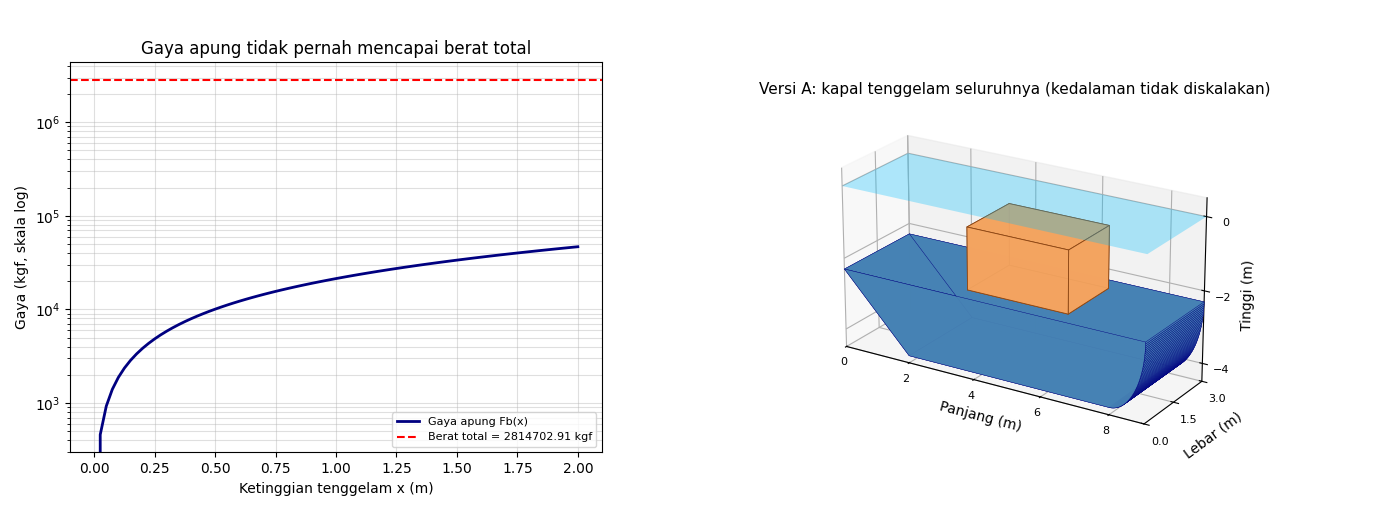

In [15]:
fig = plt.figure(figsize=(14, 5.2))
ax1 = fig.add_axes((0.05, 0.13, 0.38, 0.75))
ax1.plot(x, Fb_x, color="navy", linewidth=2, label="Gaya apung Fb(x)")
ax1.axhline(M_total_A, color="red", linestyle="--", label=f"Berat total = {M_total_A:.2f} kgf")
ax1.set_yscale("log")
ax1.set_xlabel("Ketinggian tenggelam x (m)"); ax1.set_ylabel("Gaya (kgf, skala log)")
ax1.set_title("Gaya apung tidak pernah mencapai berat total")
ax1.legend(loc="lower right", fontsize=8); ax1.grid(True, which="both", alpha=0.4)

ax = sumbu_3d(fig, (0.45, 0.0, 0.55, 0.92))
isi_kapal(ax, -4.3, air=True, muatan=True, air_depan=True)
rapikan(ax, (-4.5, 0.5), (-4, -2, 0), "Versi A: kapal tenggelam seluruhnya (kedalaman tidak diskalakan)", zoom=0.85)
plt.show()

**Interpretasi Versi A**
- **Hasil:** massa total $= 14702.91 + 2800000 = 2814702.91$ kg, sedangkan gaya apung maksimum hanya 46712.39 kgf (berat sekitar 60 kali lebih besar). $f(0) = -2814702.91$ dan $f(2) = -2767990.52$, keduanya negatif.
- **Jawaban Versi A:** tidak ada kedalaman keseimbangan. **Kapal tenggelam seluruhnya.**
- **Dari grafik dan gambar 3D:** kurva gaya apung selalu jauh di bawah garis berat, dan kapal berada seluruhnya di bawah permukaan air.
- **Satuan:** gaya dalam kgf.

### Versi B: Penyangkalan/Revisi Satuan Muatan

**Pernyataan:** Versi B memakai muatan = tiga digit terakhir NPM x 100 **kg** = 2800 kg.

**Alasan logis**
1. **Dengan satuan ton, kapal tenggelam untuk NPM berapa pun.** NPM terkecil (001) sudah memberi muatan 100 ton, lebih besar dari gaya apung maksimum 46.71 ton. Soal yang jawabannya sama untuk semua mahasiswa tidak sesuai dengan tujuan personalisasi lewat NPM.
2. **Daya angkut sisa kapal hanya 32.01 ton**, sehingga muatan 2800 ton sekitar 87 kali melebihi kemampuan kapal.
3. **Selaras dengan Soal 6.** $h_{beban} = 200 - NPM$ cm hanya positif untuk NPM di bawah 200. Dengan satuan kg, kapal mampu membawa NPM sampai sekitar 320, jadi semua NPM yang sah untuk Soal 6 juga sah untuk Soal 5.
4. Soal menanyakan "kedalaman kapal yang terendam", yang baru bermakna jika kapal mengapung.

**Catatan:** alasan ini adalah inferensi dari data soal, bukan pernyataan soal. Sebaiknya dikonfirmasi ke dosen.

**Rumus** sama seperti Versi A dengan $M_{muatan} = 2800$ kg. Akar dicari dengan **metode bagi dua**: $c = (a+b)/2$; jika $f(a)\,f(c) \le 0$ maka $b = c$, selain itu $a = c$; ulangi sampai $(b-a)/2 < 10^{-6}$ m. Hasil diperiksa dengan `scipy.optimize.brentq`.

In [16]:
sisa = Fb_max - M_kapal
print("Sisa daya angkut kapal     =", round(sisa, 2), "kg")
print("Batas NPM jika x 100 ton   =", round(sisa / 100000, 3), "(tidak ada NPM tiga digit yang mungkin)")
print("Batas NPM jika x 100 kg    =", round(sisa / 100, 1))
print()

M_total_B = M_kapal + muatan_B
f_B = lambda x: rho * volume_terendam(x) - M_total_B
print("Massa total versi B =", round(M_total_B, 2), "kg")
print("Volume yang harus terendam =", round(M_total_B / rho, 4), "m^3")
print("f(0) =", round(f_B(0), 2), "   f(2) =", round(f_B(tinggi), 2), "(beda tanda, akar ada di antara 0 dan 2)")
print()

def bisection(f, a, b, tol=1e-6):
    riwayat = []
    while (b - a) / 2 > tol:
        c = (a + b) / 2
        riwayat.append((a, b, c, f(c)))
        if f(a) * f(c) <= 0:
            b = c
        else:
            a = c
    return (a + b) / 2, riwayat

x_terendam, riwayat = bisection(f_B, 0, tinggi)
print(f"{'iter':>4s} {'a':>9s} {'b':>9s} {'c':>9s} {'f(c) (kgf)':>12s}")
for i, (a, b, c, fc) in enumerate(riwayat[:10], start=1):
    print(f"{i:4d} {a:9.5f} {b:9.5f} {c:9.5f} {fc:12.2f}")
print(" ...")
a, b, c, fc = riwayat[-1]
print(f"{len(riwayat):4d} {a:9.5f} {b:9.5f} {c:9.5f} {fc:12.2f}")
print()

x_cek = brentq(f_B, 0, tinggi)
zB_terendam = tinggi_cb(x_terendam)
print("Jumlah iterasi bagi dua       =", len(riwayat))
print("Kedalaman terendam (bagi dua) =", round(x_terendam, 4), "m")
print("Kedalaman terendam (brentq)   =", round(x_cek, 4), "m")
print("Selisih gaya apung - berat    =", round(f_B(x_terendam), 4), "kgf")
print("Kedalaman terendam            =", round(x_terendam * 100, 2), "cm")
print("Center of buoyancy saat ini   =", round(zB_terendam, 4), "m =", round(zB_terendam * 100), "cm")

Sisa daya angkut kapal     = 32009.48 kg
Batas NPM jika x 100 ton   = 0.32 (tidak ada NPM tiga digit yang mungkin)
Batas NPM jika x 100 kg    = 320.1

Massa total versi B = 17502.91 kg
Volume yang harus terendam = 17.5029 m^3
f(0) = -17502.91    f(2) = 29209.48 (beda tanda, akar ada di antara 0 dan 2)

iter         a         b         c   f(c) (kgf)
   1   0.00000   2.00000   1.00000      3839.64
   2   0.00000   1.00000   0.50000     -7447.95
   3   0.50000   1.00000   0.75000     -1935.84
   4   0.75000   1.00000   0.87500       920.47
   5   0.75000   0.87500   0.81250      -515.71
   6   0.81250   0.87500   0.84375       200.40
   7   0.81250   0.84375   0.82812      -158.15
   8   0.82812   0.84375   0.83594        21.00
   9   0.82812   0.83594   0.83203       -68.61
  10   0.83203   0.83594   0.83398       -23.81
 ...
  20   0.83502   0.83503   0.83502         0.04

Jumlah iterasi bagi dua       = 20
Kedalaman terendam (bagi dua) = 0.835 m
Kedalaman terendam (brentq)   = 0.835 m

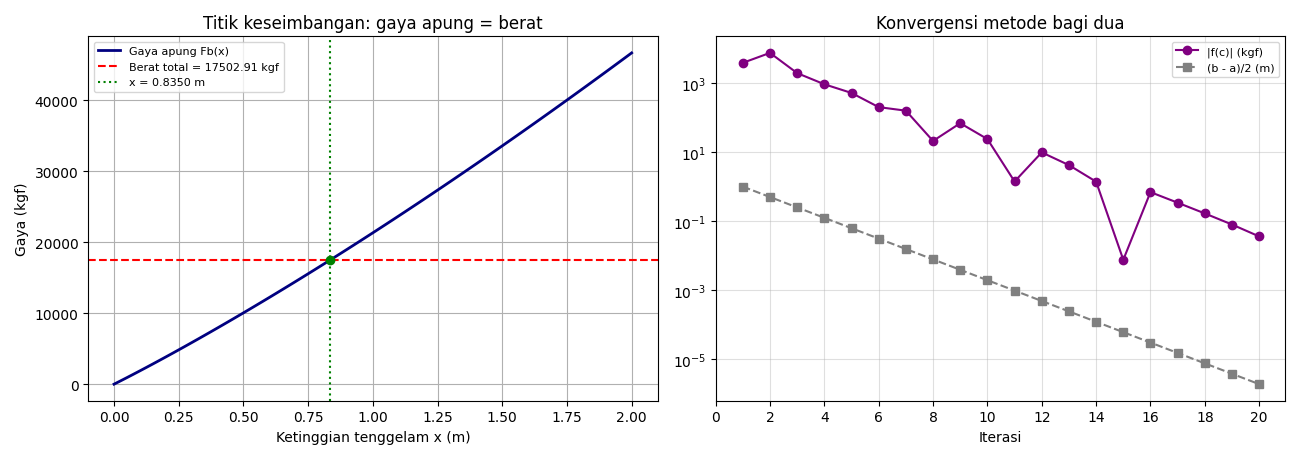

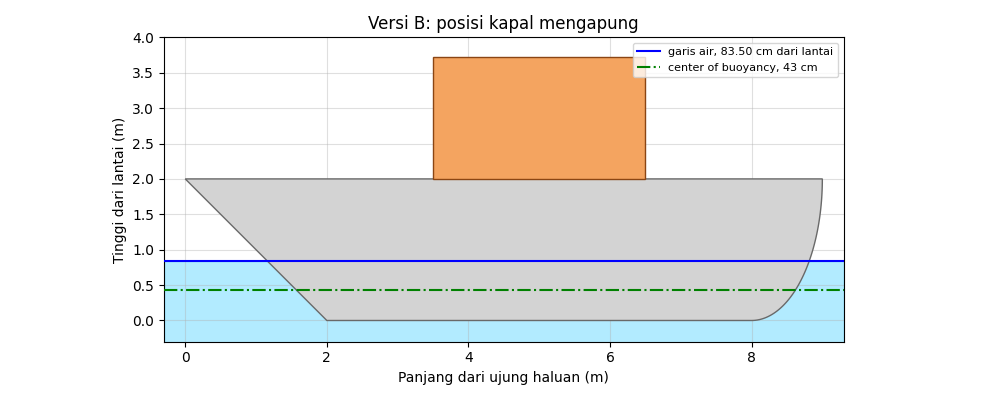

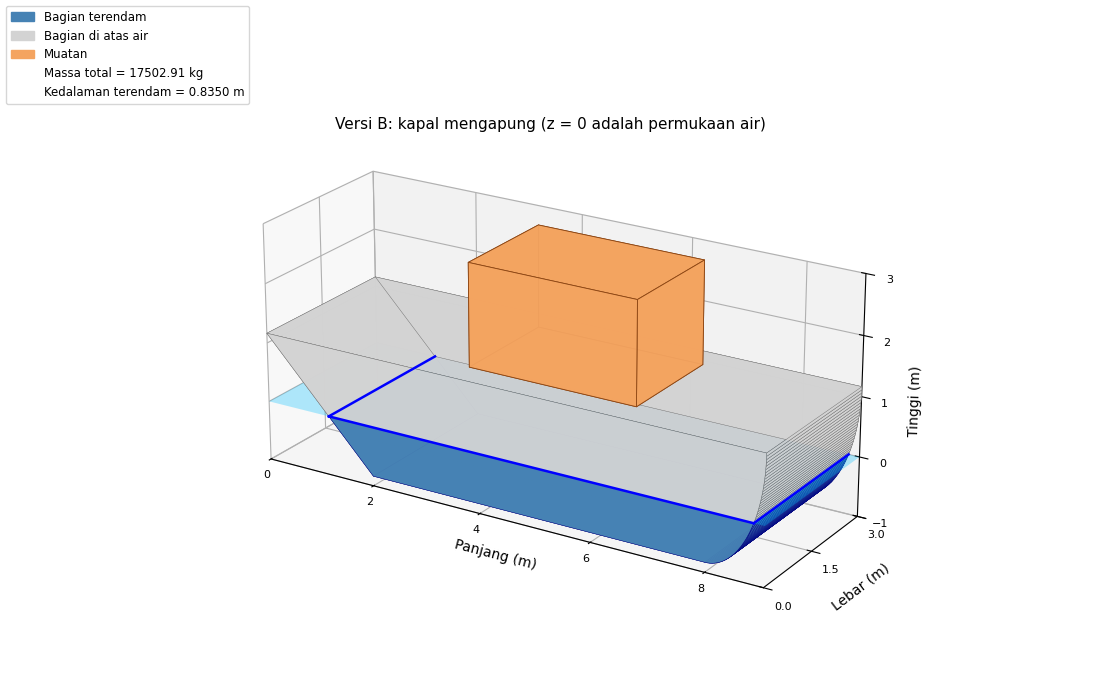

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].plot(x, Fb_x, color="navy", linewidth=2, label="Gaya apung Fb(x)")
axs[0].axhline(M_total_B, color="red", linestyle="--", label=f"Berat total = {M_total_B:.2f} kgf")
axs[0].axvline(x_terendam, color="green", linestyle=":", label=f"x = {x_terendam:.4f} m")
axs[0].scatter([x_terendam], [M_total_B], color="green", zorder=3)
axs[0].set_xlabel("Ketinggian tenggelam x (m)"); axs[0].set_ylabel("Gaya (kgf)")
axs[0].set_title("Titik keseimbangan: gaya apung = berat")
axs[0].legend(loc="upper left", fontsize=8); axs[0].grid(True)

it = np.arange(1, len(riwayat) + 1)
axs[1].semilogy(it, [abs(r[3]) for r in riwayat], "o-", color="purple", label="|f(c)| (kgf)")
axs[1].semilogy(it, [(r[1] - r[0]) / 2 for r in riwayat], "s--", color="gray", label="(b - a)/2 (m)")
axs[1].set_xlabel("Iterasi"); axs[1].set_title("Konvergensi metode bagi dua")
axs[1].set_xticks(range(0, len(riwayat) + 1, 2))
axs[1].legend(fontsize=8); axs[1].grid(True, which="both", alpha=0.4)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.axhspan(-0.4, x_terendam, color="deepskyblue", alpha=0.3, zorder=1)
profil_2d(ax, muatan=True, judul="Versi B: posisi kapal mengapung")
ax.axhline(x_terendam, color="blue", linewidth=1.5, zorder=3, label=f"garis air, {x_terendam*100:.2f} cm dari lantai")
ax.axhline(zB_terendam, color="green", linestyle="-.", zorder=3, label=f"center of buoyancy, {zB_terendam*100:.0f} cm")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(11, 7))
ax = sumbu_3d(fig)
isi_kapal(ax, -x_terendam, air=True, muatan=True)
rapikan(ax, (-1, 3), (-1, 0, 1, 2, 3), "Versi B: kapal mengapung (z = 0 adalah permukaan air)")
keterangan(fig, [f"Massa total = {M_total_B:.2f} kg", f"Kedalaman terendam = {x_terendam:.4f} m"],
           [Patch(color="steelblue", label="Bagian terendam"), Patch(color="lightgray", label="Bagian di atas air"),
            Patch(color="sandybrown", label="Muatan")])
plt.show()

**Interpretasi Versi B**
- **Hasil:** massa total $= 14702.91 + 2800 = 17502.91$ kg, sehingga volume yang harus terendam 17.5029 m³. Metode bagi dua (20 iterasi) memberi kedalaman terendam **$x = 0.8350$ m = 83.50 cm** dari lantai kapal. `brentq` memberi hasil yang sama.
- **Artinya:** kapal mengapung dengan 0.835 m lambung di bawah air dan 1.165 m di atas air. Pada kondisi ini center of buoyancy berada 0.4321 m (43 cm) dari lantai.
- **Dari grafik konvergensi:** lebar selang berkurang setengah tiap iterasi, sampai di bawah $10^{-6}$ m.
- **Dari gambar:** bagian biru adalah bagian lambung yang terendam; muatan berada di atas dek.
- **Satuan:** kedalaman dalam m (cm), gaya dalam kgf.

---
## Langkah 6: Kurva Ketinggian dari Lantai (x) vs Massa Akumulatif (y) (Versi A: Sesuai Soal)

**Tujuan**  
Menggambar massa kapal dan muatan yang berada di bawah ketinggian $x$, untuk $0 \le x \le 2 + h_{beban}$.

**Penjelasan**  
Massa akumulatif $M(x)$ adalah total massa yang terletak pada ketinggian 0 sampai $x$. Kontribusi tiap bagian:
- **alas datar** berada tepat di $z = 0$, sehingga langsung masuk penuh di $x = 0$ (lompatan pertama, 2880 kg),
- **dinding samping**: massa per satuan tinggi $= 2 \cdot 160 \cdot L(z)$,
- **bidang miring haluan**: massa per satuan tinggi $= 160 \cdot 3 \cdot \sqrt{2}$,
- **lengkung buritan**: massa sampai ketinggian $z$ dihitung lewat parameter $\theta$ (busur elips),
- **dek atas** berada tepat di $z = 2$, sehingga masuk penuh di $x = 2$ (lompatan kedua, 4320 kg),
- **muatan** terdistribusi rata secara vertikal dari $z = 2$ sampai $z = 3.72$ m, sehingga naik linear.

**Data**  
$h_{beban} = 1.72$ m, muatan Versi A $= 2800000$ kg, data pelat dari Langkah 4.

**Rumus**
$$M(x) = M_{alas} + \int_0^{\min(x,2)} 160\left[2L(z) + 3\sqrt2\right]dz + M_{lengkung}(x) + M_{dek}\,[x \ge 2] + M_{muatan}\cdot\frac{\min(\max(x-2,0),\,h_{beban})}{h_{beban}}$$
$$M_{lengkung}(x) = 160 \cdot 3 \int_0^{\theta(x)} \sqrt{a^2\cos^2\theta + b^2\sin^2\theta}\,d\theta, \qquad \theta(x) = \arccos\frac{2 - x}{b}$$

In [18]:
M_alas = berat_baja * A_alas
M_dek  = berat_baja * A_dek

def massa_dinding_miring(z):
    z = min(z, tinggi)
    return berat_baja * 2 * quad(L, 0, z)[0] + berat_baja * lebar * np.sqrt(2) * z

def massa_lengkung(z):
    z = min(z, tinggi)
    return berat_baja * lebar * quad(ds, 0, np.arccos((tinggi - z) / b_elips))[0]

def massa_akumulatif(xx, muatan):
    m = M_alas + massa_dinding_miring(xx) + massa_lengkung(xx)
    if xx >= tinggi:
        m += M_dek
    if xx > tinggi:
        m += muatan * min(xx - tinggi, h_beban) / h_beban
    return m

print("Pemeriksaan: M(2) tanpa muatan =", round(massa_akumulatif(tinggi, 0), 2), "kg; massa kapal Langkah 4 =", round(M_kapal, 2), "kg")
print()
titik_m = [0, 0.5, 1.0, 1.5, 2 - 1e-9, 2.0, 2.43, 2.86, 3.29, 2 + h_beban]
print(f"{'x (m)':>7s} {'M versi A (kg)':>16s}")
for xx in titik_m:
    label = "2 (bawah dek)" if abs(xx - 2) < 1e-6 and xx < 2 else f"{xx:.2f}"
    print(f"{label:>13s} {massa_akumulatif(xx, muatan_A):16.2f}")

x_m = np.concatenate([np.linspace(0, tinggi - 1e-9, 120), np.linspace(tinggi, tinggi + h_beban, 80)])
MA = np.array([massa_akumulatif(v, muatan_A) for v in x_m])

Pemeriksaan: M(2) tanpa muatan = 14702.91 kg; massa kapal Langkah 4 = 14702.91 kg

  x (m)   M versi A (kg)
         0.00          2880.00
         0.50          4708.81
         1.00          6512.13
         1.50          8404.54
2 (bawah dek)         10382.91
         2.00         14702.91
         2.43        714702.91
         2.86       1414702.91
         3.29       2114702.91
         3.72       2814702.91


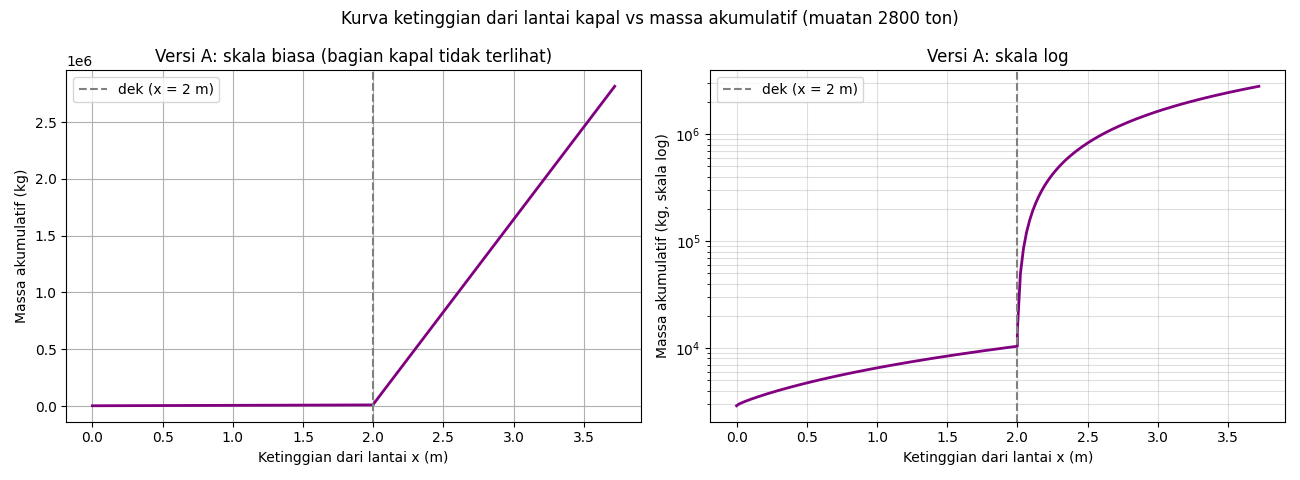

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].plot(x_m, MA, color="purple", linewidth=2)
axs[0].axvline(tinggi, color="gray", linestyle="--", label="dek (x = 2 m)")
axs[0].set_xlabel("Ketinggian dari lantai x (m)"); axs[0].set_ylabel("Massa akumulatif (kg)")
axs[0].set_title("Versi A: skala biasa (bagian kapal tidak terlihat)")
axs[0].legend(loc="upper left"); axs[0].grid(True)

axs[1].plot(x_m, MA, color="purple", linewidth=2)
axs[1].axvline(tinggi, color="gray", linestyle="--", label="dek (x = 2 m)")
axs[1].set_yscale("log")
axs[1].set_xlabel("Ketinggian dari lantai x (m)"); axs[1].set_ylabel("Massa akumulatif (kg, skala log)")
axs[1].set_title("Versi A: skala log")
axs[1].legend(loc="upper left"); axs[1].grid(True, which="both", alpha=0.4)
fig.suptitle("Kurva ketinggian dari lantai kapal vs massa akumulatif (muatan 2800 ton)")
plt.tight_layout(); plt.show()

**Interpretasi Versi A**
- **Hasil:** sampai $x = 2$ m kurva sama dengan Versi B (2880 kg di $x = 0$, 10382.91 kg tepat di bawah dek, 14702.91 kg di dek). Di atas dek, muatan 2800 ton membuat kurva naik linear sangat curam sampai **2814702.91 kg** di $x = 3.72$ m.
- **Artinya:** muatan menyumbang 99.48% massa total, sehingga pada skala biasa bagian kapal hampir tidak terlihat; skala log dipakai untuk memperlihatkannya.
- **Satuan:** $x$ dalam m, massa dalam kg.

### Versi B: Penyangkalan/Revisi Satuan Muatan

Dengan alasan yang sama seperti Langkah 5, muatan = 2800 kg. Fungsi `massa_akumulatif` yang sama dipakai, hanya nilai muatannya yang berubah.

        x (m)   M versi B (kg)
         0.00          2880.00
         0.50          4708.81
         1.00          6512.13
         1.50          8404.54
2 (bawah dek)         10382.91
         2.00         14702.91
         2.43         15402.91
         2.86         16102.91
         3.29         16802.91
         3.72         17502.91


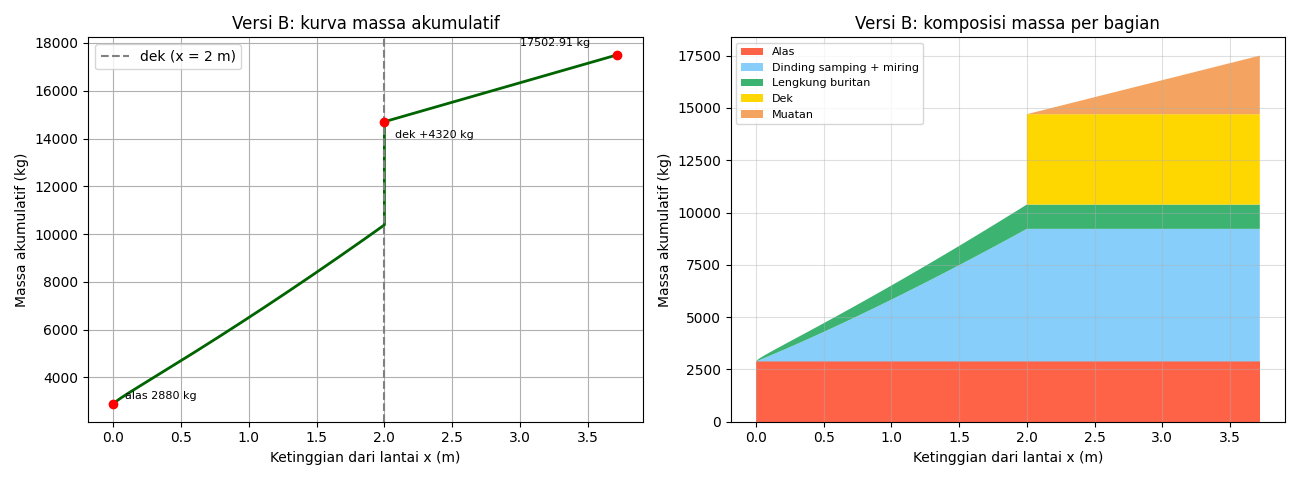

In [20]:
MB = np.array([massa_akumulatif(v, muatan_B) for v in x_m])
print(f"{'x (m)':>13s} {'M versi B (kg)':>16s}")
for xx in titik_m:
    label = "2 (bawah dek)" if abs(xx - 2) < 1e-6 and xx < 2 else f"{xx:.2f}"
    print(f"{label:>13s} {massa_akumulatif(xx, muatan_B):16.2f}")

# komposisi massa akumulatif per bagian
komp_alas = np.full_like(x_m, M_alas)
komp_dm   = np.array([massa_dinding_miring(v) for v in x_m])
komp_lk   = np.array([massa_lengkung(v) for v in x_m])
komp_dek  = np.where(x_m >= tinggi, M_dek, 0.0)
komp_mu   = np.array([muatan_B * min(max(v - tinggi, 0), h_beban) / h_beban for v in x_m])

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].plot(x_m, MB, color="darkgreen", linewidth=2)
axs[0].axvline(tinggi, color="gray", linestyle="--", label="dek (x = 2 m)")
for xx, yy, teks, off in [(0, M_alas, "alas 2880 kg", (8, 4)), (tinggi, M_kapal, "dek +4320 kg", (8, -12)),
                          (tinggi + h_beban, M_total_B, f"{M_total_B:.2f} kg", (-70, 6))]:
    axs[0].scatter([xx], [yy], color="red", zorder=3)
    axs[0].annotate(teks, (xx, yy), textcoords="offset points", xytext=off, fontsize=8)
axs[0].set_xlabel("Ketinggian dari lantai x (m)"); axs[0].set_ylabel("Massa akumulatif (kg)")
axs[0].set_title("Versi B: kurva massa akumulatif")
axs[0].legend(loc="upper left"); axs[0].grid(True)

axs[1].stackplot(x_m, komp_alas, komp_dm, komp_lk, komp_dek, komp_mu,
                 labels=["Alas", "Dinding samping + miring", "Lengkung buritan", "Dek", "Muatan"],
                 colors=["tomato", "lightskyblue", "mediumseagreen", "gold", "sandybrown"])
axs[1].set_xlabel("Ketinggian dari lantai x (m)"); axs[1].set_ylabel("Massa akumulatif (kg)")
axs[1].set_title("Versi B: komposisi massa per bagian")
axs[1].legend(loc="upper left", fontsize=8); axs[1].grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

**Interpretasi Versi B**
- **Hasil:** $M(x)$ mulai dari **2880 kg** di $x = 0$ (pelat alas), naik melengkung sampai **10382.91 kg** tepat di bawah dek, melompat ke **14702.91 kg** di $x = 2$ m (pelat dek 4320 kg), lalu naik linear sampai **17502.91 kg** di $x = 3.72$ m.
- **Pemeriksaan:** $M(2)$ dari integral sama dengan massa kapal Langkah 4.
- **Artinya:** dua lompatan menunjukkan massa yang terpusat pada satu ketinggian (alas dan dek). Bagian melengkung menunjukkan massa dinding yang makin banyak ke atas karena kapal melebar. Bagian linear adalah muatan yang terdistribusi rata.
- **Satuan:** $x$ dalam m, massa dalam kg.

---
## Langkah 7: Ketinggian Center of Mass dari Lantai Kapal beserta Muatan (Versi A: Sesuai Soal)

**Tujuan**  
Menentukan tinggi center of mass gabungan kapal dan muatan dari lantai kapal, dengan ketelitian cm.

**Penjelasan**  
Titik berat gabungan adalah rata-rata tinggi titik berat tiap benda yang dibobot dengan massanya.
- **Muatan:** homogen, sehingga titik beratnya di tengah tinggi balok: $z_{muatan} = 2 + 1.72/2 = 2.86$ m.
- **Baja:** rata-rata titik berat tiap pelat dibobot luasnya. Dek di $z = 2$, alas di $z = 0$, bidang miring di $z = 1$, dinding samping di titik berat profil ($z_B$ penuh = 1.0581 m), dan lengkung buritan di titik berat busur elips (dihitung numerik).
- Hasil baja diperiksa dengan cara kedua: integral $\int z\,dM$ dari distribusi massa Langkah 6.

**Data**  
Luas tiap pelat dari Langkah 4, $M_{kapal} = 14702.91$ kg, $M_{muatan} = 2800000$ kg (sesuai soal). Titik berat gabungan hanyalah rata-rata berbobot, sehingga tetap dapat dihitung walaupun kapal tenggelam.

**Rumus**
$$\bar z_{busur} = \frac{1}{s}\int_0^{\pi/2} (2 - b\cos\theta)\,\sqrt{a^2\cos^2\theta + b^2\sin^2\theta}\,d\theta$$
$$z_{baja} = \frac{\sum A_i z_i}{\sum A_i} \qquad z_G = \frac{M_{kapal}\,z_{baja} + M_{muatan}\,z_{muatan}}{M_{kapal} + M_{muatan}}$$

In [21]:
z_muatan = tinggi + h_beban / 2
z_lengkung = quad(lambda t: (tinggi - b_elips * np.cos(t)) * ds(t), 0, np.pi / 2)[0] / s_busur

bagian_pelat = [
    ("Dek atas",                A_dek,      tinggi),
    ("Alas datar",              A_alas,     0.0),
    ("Bidang miring haluan",    A_miring,   tinggi / 2),
    ("Dua dinding samping",     A_sisi,     zB_penuh),
    ("Bidang lengkung buritan", A_lengkung, z_lengkung),
]
momen = 0
for nama_p, A, z in bagian_pelat:
    print(f"{nama_p:25s} A = {A:8.4f} m^2   z = {z:.4f} m   A*z = {A*z:9.4f}")
    momen += A * z
z_baja = momen / A_total
print(f"{'Jumlah':25s} A = {A_total:8.4f} m^2                  A*z = {momen:9.4f}")
print()
print("z titik berat baja   =", round(z_baja, 4), "m")

# cara kedua: integral z dM (dinding + miring + lengkung) + dek di z = 2 + alas di z = 0
momen_int = quad(lambda z: z * berat_baja * (2 * L(z) + lebar * np.sqrt(2)), 0, tinggi)[0]
momen_int += quad(lambda t: (tinggi - b_elips * np.cos(t)) * berat_baja * lebar * ds(t), 0, np.pi / 2)[0]
momen_int += M_dek * tinggi
print("z baja (integral z dM) =", round(momen_int / M_kapal, 4), "m")
print("z titik berat muatan   =", round(z_muatan, 4), "m")

def z_gabungan(muatan):
    return (M_kapal * z_baja + muatan * z_muatan) / (M_kapal + muatan)

z_G_A = z_gabungan(muatan_A)
print()
print("Momen kapal  = M_kapal * z_baja   =", round(M_kapal * z_baja, 2), "kg.m")
print("Momen muatan = M_muatan * z_muatan =", round(muatan_A * z_muatan, 2), "kg.m")
print("Versi A: center of mass =", round(z_G_A, 4), "m =", round(z_G_A * 100), "cm")
print("Porsi muatan            =", round(muatan_A / (M_kapal + muatan_A) * 100, 2), "%")

Dek atas                  A =  27.0000 m^2   z = 2.0000 m   A*z =   54.0000
Alas datar                A =  18.0000 m^2   z = 0.0000 m   A*z =    0.0000
Bidang miring haluan      A =   8.4853 m^2   z = 1.0000 m   A*z =    8.4853
Dua dinding samping       A =  31.1416 m^2   z = 1.0581 m   A*z =   32.9499
Bidang lengkung buritan   A =   7.2663 m^2   z = 0.8604 m   A*z =    6.2516
Jumlah                    A =  91.8932 m^2                  A*z =  101.6868

z titik berat baja   = 1.1066 m
z baja (integral z dM) = 1.1066 m
z titik berat muatan   = 2.86 m

Momen kapal  = M_kapal * z_baja   = 16269.88 kg.m
Momen muatan = M_muatan * z_muatan = 8008000.0 kg.m
Versi A: center of mass = 2.8508 m = 285 cm
Porsi muatan            = 99.48 %


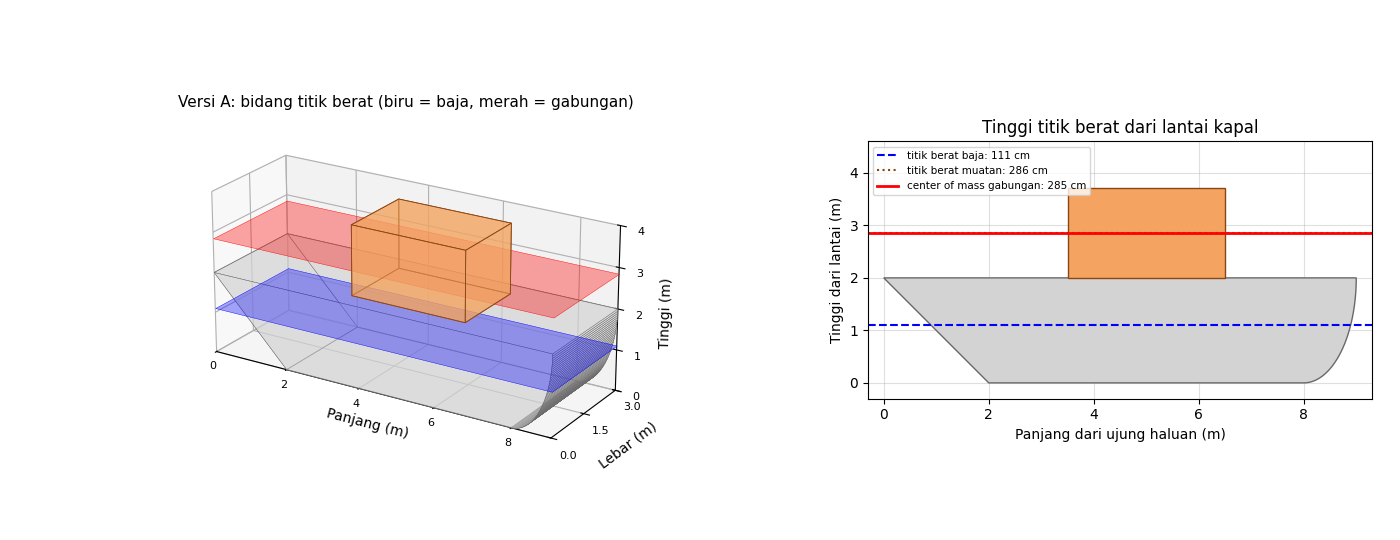

In [22]:
def gambar_titik_berat(z_G, judul, dz, air):
    fig = plt.figure(figsize=(14, 5.4))
    ax = sumbu_3d(fig, (0.0, 0.0, 0.58, 0.9))
    isi_kapal(ax, dz, air=air, muatan=True, alpha_lambung=0.45, alpha_muatan=0.55)
    bidang = lambda z, w: tambah(ax, [[(0, 0, z + dz), (9, 0, z + dz), (9, 3, z + dz), (0, 3, z + dz)]], w, w, 0.35, 6)
    bidang(z_baja, "blue"); bidang(z_G, "red")
    if dz < 0:
        rapikan(ax, (-1, 3), (-1, 0, 1, 2, 3), judul, zoom=0.9)
    else:
        rapikan(ax, (0, 4), (0, 1, 2, 3, 4), judul, zoom=0.9)
    ax2 = fig.add_axes((0.62, 0.15, 0.36, 0.7))
    profil_2d(ax2, muatan=True, judul="Tinggi titik berat dari lantai kapal")
    ax2.axhline(z_baja, color="blue", linestyle="--", label=f"titik berat baja: {z_baja*100:.0f} cm")
    ax2.axhline(z_muatan, color="saddlebrown", linestyle=":", label=f"titik berat muatan: {z_muatan*100:.0f} cm")
    ax2.axhline(z_G, color="red", linewidth=2, label=f"center of mass gabungan: {z_G*100:.0f} cm")
    ax2.set_ylim(-0.3, 4.6)
    ax2.legend(loc="upper left", fontsize=7.5, ncol=1)
    plt.show()

gambar_titik_berat(z_G_A, "Versi A: bidang titik berat (biru = baja, merah = gabungan)", 0, air=False)

**Interpretasi Versi A**
- **Hasil:** $z_{baja} = 101.6868 / 91.8932 = 1.1066$ m (cara integral $\int z\,dM$ memberi nilai sama). $z_G = \dfrac{16269.88 + 2800000(2.86)}{2814702.91} = \dfrac{8024269.88}{2814702.91} = \mathbf{2.8508}$ m, dibulatkan **2.85 m = 285 cm** dari lantai kapal.
- **Artinya:** muatan menyumbang 99.48% massa total, sehingga titik berat gabungan hampir sama dengan titik berat muatan (2.86 m). Pada Versi A kapal tenggelam (Soal 5), jadi nilai ini hanya letak titik berat kumpulan baja dan muatan.
- **Dari gambar:** bidang merah (gabungan) hampir berimpit dengan titik berat muatan dan jauh di atas bidang biru (baja).
- **Satuan:** meter (cm).

### Versi B: Penyangkalan/Revisi Satuan Muatan

Dengan alasan yang sama seperti Langkah 5, muatan = 2800 kg. Titik berat baja dan muatan tidak berubah; hanya bobot muatan yang berubah.

Momen kapal  = 16269.88 kg.m
Momen muatan = 8008.0 kg.m
Massa total  = 17502.91 kg
Versi B: center of mass = 1.3871 m = 139 cm
Porsi muatan            = 16.0 %
Center of buoyancy saat mengapung (Langkah 5) = 43 cm


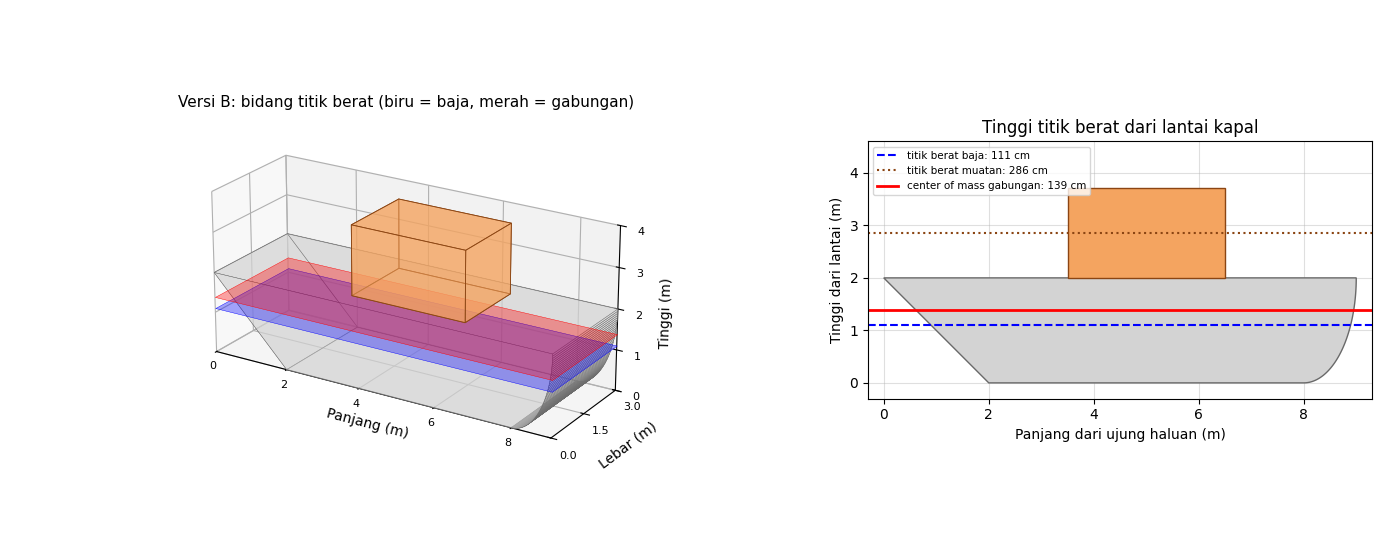

In [23]:
z_G_B = z_gabungan(muatan_B)
print("Momen kapal  =", round(M_kapal * z_baja, 2), "kg.m")
print("Momen muatan =", round(muatan_B * z_muatan, 2), "kg.m")
print("Massa total  =", round(M_total_B, 2), "kg")
print("Versi B: center of mass =", round(z_G_B, 4), "m =", round(z_G_B * 100), "cm")
print("Porsi muatan            =", round(muatan_B / M_total_B * 100, 2), "%")
print("Center of buoyancy saat mengapung (Langkah 5) =", round(zB_terendam * 100), "cm")

gambar_titik_berat(z_G_B, "Versi B: bidang titik berat (biru = baja, merah = gabungan)", 0, air=False)

**Interpretasi Versi B**
- **Hasil:** $z_G = \dfrac{16269.88 + 2800(2.86)}{17502.91} = \dfrac{24277.88}{17502.91} = \mathbf{1.3871}$ m, dibulatkan **1.39 m = 139 cm** dari lantai kapal.
- **Artinya:** muatan hanya 16% dari massa total, sehingga titik berat gabungan hanya naik 28 cm dari titik berat baja (111 cm).
- **Catatan stabilitas:** center of mass (139 cm) berada di atas center of buoyancy (43 cm). Hal ini wajar untuk kapal; kestabilan sebenarnya ditentukan oleh letak metacenter, yang tidak ditanyakan soal.
- **Satuan:** meter (cm).

---
## Ringkasan Hasil Perhitungan

**Kode:** mencetak seluruh hasil dari variabel yang sama agar angkanya konsisten dengan langkah sebelumnya.

In [24]:
print("RINGKASAN HASIL - Oline Ola Fadhillah (NPM 25083010028)")
print("=" * 72)
print("Soal 1 sampai 4 sama untuk kedua versi")
print(f"1) Volume total                         : {V_total:.4f} m^3")
print(f"   Gaya apung maksimum                  : {Fb_max:.2f} kgf ({Fb_max*g:.2f} N)")
print(f"2) Kurva Fb(x), x = 0 s.d. 2 m          : 0 s.d. {Fb_x[-1]:.2f} kgf")
print(f"3) Center of buoyancy (terendam penuh)  : {zB_penuh:.4f} m ({zB_penuh*100:.0f} cm)")
print(f"4) Massa total kapal                    : {M_kapal:.2f} kg")
print()
print("VERSI A (sesuai soal: muatan 2800 ton)")
print(f"5) Kedalaman terendam                   : tidak ada keseimbangan, kapal tenggelam")
print(f"6) Massa akumulatif di x = 3.72 m       : {massa_akumulatif(2 + h_beban, muatan_A):.2f} kg")
print(f"7) Center of mass                       : {z_G_A:.4f} m ({z_G_A*100:.0f} cm)")
print()
print("VERSI B (revisi: muatan 2800 kg)")
print(f"5) Kedalaman terendam                   : {x_terendam:.4f} m ({x_terendam*100:.2f} cm)")
print(f"   Center of buoyancy saat mengapung    : {zB_terendam:.4f} m ({zB_terendam*100:.0f} cm)")
print(f"6) Massa akumulatif di x = 3.72 m       : {massa_akumulatif(2 + h_beban, muatan_B):.2f} kg")
print(f"7) Center of mass                       : {z_G_B:.4f} m ({z_G_B*100:.0f} cm)")

RINGKASAN HASIL - Oline Ola Fadhillah (NPM 25083010028)
Soal 1 sampai 4 sama untuk kedua versi
1) Volume total                         : 46.7124 m^3
   Gaya apung maksimum                  : 46712.39 kgf (458248.54 N)
2) Kurva Fb(x), x = 0 s.d. 2 m          : 0 s.d. 46712.39 kgf
3) Center of buoyancy (terendam penuh)  : 1.0581 m (106 cm)
4) Massa total kapal                    : 14702.91 kg

VERSI A (sesuai soal: muatan 2800 ton)
5) Kedalaman terendam                   : tidak ada keseimbangan, kapal tenggelam
6) Massa akumulatif di x = 3.72 m       : 2814702.91 kg
7) Center of mass                       : 2.8508 m (285 cm)

VERSI B (revisi: muatan 2800 kg)
5) Kedalaman terendam                   : 0.8350 m (83.50 cm)
   Center of buoyancy saat mengapung    : 0.4321 m (43 cm)
6) Massa akumulatif di x = 3.72 m       : 17502.91 kg
7) Center of mass                       : 1.3871 m (139 cm)


---
# Kesimpulan Akhir dan Langkah Penyelesaian ETS

**Cara membaca bagian ini.** Setiap soal ditulis dengan urutan *Diketahui, Ditanya, Penyelesaian, Jawaban*, sehingga dapat disalin ke lembar jawaban. Soal 5, 6, dan 7 memiliki **Versi A (sesuai soal)** sebagai jawaban utama dan **Versi B (revisi)** beserta alasannya. Semua angka berasal dari kode di atas (Oline Ola Fadhillah, NPM 25083010028; tiga digit terakhir 028).

## Data dan simbol

| Simbol | Arti | Nilai |
|---|---|---|
| $p_h$, $p_t$ | panjang haluan, panjang badan tengah | 2 m, 6 m |
| $a$, $b$ | semi-sumbu elips buritan (horizontal, vertikal) | 1 m, 2 m |
| $l$, $t$ | lebar kapal, tinggi lambung | 3 m, 2 m |
| $\rho$ | massa jenis air | 1000 kg/m³ |
| $\sigma$ | berat jenis pelat baja | 160 kg/m² |
| $x$, $z$ | ketinggian dari lantai kapal | m |
| $L(z)$ | panjang penampang lambung pada ketinggian $z$ | m |
| $V$, $F_b$ | volume terendam, gaya apung $= \rho V$ | m³, kgf |

**Bentuk kapal.** Panjang total 2 + 6 + 1 = 9 m. Haluan prisma segitiga (2 m x 2 m, sudut 45°), badan tengah balok, buritan seperempat silinder elips $\dfrac{x^2}{1^2} + \dfrac{(y-2)^2}{2^2} = 1$. Lebar seluruh kapal 3 m. 1 kgf = 9.81 N.

## Soal 1: Volume total dan gaya apung maksimum

**Diketahui:** $p_h = 2$ m, $p_t = 6$ m, $a = 1$ m, $b = 2$ m, $l = 3$ m, $t = 2$ m, $\rho = 1000$ kg/m³.  
**Ditanya:** volume total kapal dan gaya apung maksimum.

**Penyelesaian:**
1. Kapal dibagi tiga bagian, masing-masing volume = luas profil samping x lebar.
2. Haluan: luas segitiga $= \tfrac12 \times 2 \times 2 = 2$ m², maka $V_h = 2 \times 3 = 6$ m³.
3. Badan tengah: luas persegi panjang $= 6 \times 2 = 12$ m², maka $V_t = 12 \times 3 = 36$ m³.
4. Buritan: luas seperempat elips $= \tfrac14 \pi a b = \tfrac14 \pi (1)(2) = 1.5708$ m², maka $V_b = 1.5708 \times 3 = 4.7124$ m³.
5. $V = 6 + 36 + 4.7124 = 46.7124$ m³ (integral numerik $3\int_0^2 L(z)\,dz$ memberi nilai sama).
6. Gaya apung maksimum saat seluruh lambung terendam: $F_b = \rho V = 1000 \times 46.7124 = 46712.39$ kgf $= 46712.39 \times 9.81 = 458248.54$ N.

**Jawaban:** $V = \mathbf{46.7124}$ m³ dan $F_{b,maks} = \mathbf{46712.39}$ kgf $\approx$ 46.71 ton $\approx$ 458248.54 N.

## Soal 2: Kurva ketinggian tenggelam $(x)$ vs gaya apung $(y)$

**Diketahui:** $0 \le x \le 2$ m, $\rho = 1000$ kg/m³.  
**Ditanya:** grafik $x$ (sumbu mendatar) terhadap $F_b$ (sumbu tegak).

**Penyelesaian:**
1. Panjang irisan pada ketinggian $z$: $L(z) = z + 6 + \sqrt{1 - (z-2)^2/4}$.
2. Volume terendam sedalam $x$: $V(x) = 3\int_0^x L(z)\,dz = 1.5x^2 + 18x + 3\int_0^x \sqrt{1 - (z-2)^2/4}\,dz$. Suku terakhir (buritan) dihitung numerik.
3. Gaya apung: $F_b(x) = 1000\,V(x)$.

| $x$ (m) | $1.5x^2$ | $18x$ | $V_b(x)$ | $V(x)$ (m³) | $F_b$ (kgf) |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 | 0 |
| 0.5 | 0.3750 | 9 | 0.6800 | 10.0550 | 10054.97 |
| 1.0 | 1.5000 | 18 | 1.8426 | 21.3426 | 21342.55 |
| 1.5 | 3.3750 | 27 | 3.2282 | 33.6032 | 33603.16 |
| 2.0 | 6.0000 | 36 | 4.7124 | 46.7124 | 46712.39 |

4. Titik-titik tersebut digambar dan dihubungkan (81 titik pada notebook).

**Jawaban:** kurva naik dari 0 sampai 46712.39 kgf dan makin curam ke atas, karena kemiringannya $dF_b/dx = 3000\,L(x)$ naik dari 18000 kgf/m di lantai menjadi 27000 kgf/m di dek.

## Soal 3: Ketinggian center of buoyancy

**Diketahui:** kapal terendam penuh; profil samping = segitiga + persegi panjang + seperempat elips.  
**Ditanya:** tinggi center of buoyancy $z_B$ dari lantai (ketelitian cm).

**Penyelesaian:**
1. CB = titik berat volume terendam. Lebar tetap, sehingga cukup titik berat profil: $z_B = \dfrac{\sum A_i z_i}{\sum A_i}$.
2. Segitiga haluan: $A_1 = 2$ m², $z_1 = \dfrac{2 + 2 + 0}{3} = 1.3333$ m.
3. Persegi panjang tengah: $A_2 = 12$ m², $z_2 = 1$ m.
4. Seperempat elips: $A_3 = 1.5708$ m², $z_3 = 2 - \dfrac{4b}{3\pi} = 2 - \dfrac{8}{3\pi} = 1.1512$ m.
5. $z_B = \dfrac{2(1.3333) + 12(1) + 1.5708(1.1512)}{2 + 12 + 1.5708} = \dfrac{16.4749}{15.5708} = 1.0581$ m. Integral numerik $\int z L\,dz / \int L\,dz$ memberi nilai sama.

**Jawaban:** $z_B = 1.0581$ m $\approx$ **106 cm** dari lantai kapal.

## Soal 4: Massa total kapal

**Diketahui:** berat jenis baja 160 kg/m², termasuk dek atas.  
**Ditanya:** massa total kapal.

**Penyelesaian:**
1. Panjang busur seperempat elips (integral numerik): $s = \int_0^{\pi/2}\sqrt{\cos^2\theta + 4\sin^2\theta}\,d\theta = 2.4221$ m.
2. Luas tiap pelat:

| Pelat | Perhitungan | Luas (m²) |
|---|---|---|
| Dek atas | $9 \times 3$ | 27.0000 |
| Alas datar | $6 \times 3$ | 18.0000 |
| Bidang miring haluan | $2\sqrt2 \times 3$ | 8.4853 |
| Dua dinding samping | $2 \times 15.5708$ | 31.1416 |
| Lengkung buritan | $2.4221 \times 3$ | 7.2663 |
| **Total** | | **91.8932** |

3. $M = 160 \times 91.8932 = 14702.91$ kg.

**Jawaban:** massa total kapal **14702.91 kg** $\approx$ 14.70 ton.

## Soal 5: Kedalaman kapal yang terendam

**Diketahui:** $M_{kapal} = 14702.91$ kg, NPM 028, $F_{b,maks} = 46712.39$ kgf.  
**Ditanya:** kedalaman terendam $x$, dari $f(x) = 1000\,V(x) - M_{total} = 0$.

**Versi A (sesuai soal, muatan $28 \times 100$ ton $= 2800000$ kg):**
1. $M_{total} = 14702.91 + 2800000 = 2814702.91$ kg.
2. $f(0) = -2814702.91$ dan $f(2) = 46712.39 - 2814702.91 = -2767990.52$. Keduanya negatif, jadi tidak ada akar di $0 \le x \le 2$.

**Jawaban Versi A:** tidak ada kedalaman keseimbangan, **kapal tenggelam seluruhnya**.

**Versi B (revisi, muatan $28 \times 100$ kg $= 2800$ kg):**
1. $M_{total} = 14702.91 + 2800 = 17502.91$ kg, volume yang harus terendam 17.5029 m³.
2. $f(0) = -17502.91 < 0$ dan $f(2) = 29209.48 > 0$, jadi akar berada di antara 0 dan 2 m.
3. Metode bagi dua:

| Iterasi | $a$ | $b$ | $c$ | $f(c)$ (kgf) |
|---|---|---|---|---|
| 1 | 0 | 2 | 1 | 3839.64 |
| 2 | 0 | 1 | 0.5 | -7447.95 |
| 3 | 0.5 | 1 | 0.75 | -1935.84 |
| 4 | 0.75 | 1 | 0.875 | 920.47 |
| 5 | 0.75 | 0.875 | 0.8125 | -515.71 |
| 6 | 0.8125 | 0.875 | 0.84375 | 200.40 |

4. Iterasi dilanjutkan sampai iterasi ke-20 (toleransi $10^{-6}$ m), diperoleh $x = 0.8350$ m; `brentq` memberi hasil sama.

**Jawaban Versi B:** kedalaman terendam **83.50 cm** dari lantai kapal. (Center of buoyancy pada kondisi ini 43 cm.)

*Alasan Versi B:* dengan satuan ton, NPM terkecil (001) pun memberi muatan 100 ton, melebihi gaya apung maksimum 46.71 ton, sehingga semua mahasiswa pasti mendapat jawaban "tenggelam". Dengan satuan kg, kapal mampu membawa NPM sampai sekitar 320, selaras dengan syarat $h_{beban} = 200 - NPM > 0$ pada Soal 6.

## Soal 6: Kurva ketinggian dari lantai $(x)$ vs massa akumulatif $(y)$

**Diketahui:** $h_{beban} = 200 - 28 = 172$ cm, muatan terdistribusi rata secara vertikal dari 2 m sampai 3.72 m.  
**Ditanya:** grafik $x$ terhadap massa akumulatif $M(x)$.

**Penyelesaian:**
1. Alas (2880 kg) berada di $x = 0$, sehingga kurva mulai dari 2880 kg.
2. Untuk $0 < x < 2$: dinding samping, bidang miring, dan lengkung buritan bertambah sesuai tinggi (integral numerik), total 7502.91 kg sampai tepat di bawah dek.
3. Di $x = 2$ m pelat dek (4320 kg) masuk, sehingga $M = 14702.91$ kg.
4. Untuk $2 < x \le 3.72$: $M(x) = 14702.91 + M_{muatan}\,\dfrac{x - 2}{1.72}$.

| $x$ (m) | 0 | 0.5 | 1.0 | 1.5 | 2 (bawah dek) | 2 | 2.86 | 3.72 |
|---|---|---|---|---|---|---|---|---|
| Versi B (kg) | 2880.00 | 4708.81 | 6512.13 | 8404.54 | 10382.91 | 14702.91 | 16102.91 | 17502.91 |
| Versi A (kg) | 2880.00 | 4708.81 | 6512.13 | 8404.54 | 10382.91 | 14702.91 | 1414702.91 | 2814702.91 |

**Jawaban:** kurva melompat di $x = 0$ dan $x = 2$ m, melengkung di antaranya, lalu naik linear di atas dek. Nilai akhir **Versi A 2814702.91 kg**, **Versi B 17502.91 kg**.

## Soal 7: Ketinggian center of mass beserta muatan

**Diketahui:** luas pelat dari Soal 4, $M_{kapal} = 14702.91$ kg, $h_{beban} = 1.72$ m.  
**Ditanya:** tinggi center of mass gabungan dari lantai (ketelitian cm).

**Penyelesaian:**
1. Titik berat muatan: $z_{muatan} = 2 + 1.72/2 = 2.86$ m.
2. Titik berat baja dari titik berat tiap pelat (busur buritan dihitung numerik):

| Pelat | $A$ (m²) | $z$ (m) | $A \cdot z$ |
|---|---|---|---|
| Dek atas | 27.0000 | 2.0000 | 54.0000 |
| Alas datar | 18.0000 | 0.0000 | 0.0000 |
| Bidang miring haluan | 8.4853 | 1.0000 | 8.4853 |
| Dua dinding samping | 31.1416 | 1.0581 | 32.9499 |
| Lengkung buritan | 7.2663 | 0.8604 | 6.2516 |
| **Jumlah** | **91.8932** | | **101.6868** |

3. $z_{baja} = 101.6868 / 91.8932 = 1.1066$ m, sehingga momen kapal $= 14702.91 \times 1.1066 = 16269.88$ kg·m.
4. $z_G = \dfrac{16269.88 + M_{muatan} \times 2.86}{14702.91 + M_{muatan}}$.

**Versi A** ($M_{muatan} = 2800000$ kg): $z_G = \dfrac{16269.88 + 8008000}{2814702.91} = 2.8508$ m $\approx$ **285 cm**.  
**Versi B** ($M_{muatan} = 2800$ kg): $z_G = \dfrac{16269.88 + 8008}{17502.91} = 1.3871$ m $\approx$ **139 cm**.

## Rekapitulasi hasil

| No | Besaran | Versi A (sesuai soal) | Versi B (revisi) | Satuan |
|---|---|---|---|---|
| 1 | Volume total kapal | 46.7124 | 46.7124 | m³ |
| 1 | Gaya apung maksimum | 46712.39 | 46712.39 | kgf |
| 2 | Kurva $F_b(x)$, $x$ = 0 s.d. 2 m | naik, 0 s.d. 46712.39 | naik, 0 s.d. 46712.39 | kgf |
| 3 | Center of buoyancy (terendam penuh) | 106 | 106 | cm |
| 4 | Massa total kapal | 14702.91 | 14702.91 | kg |
| 5 | Kedalaman terendam | kapal tenggelam | 83.50 | cm |
| 6 | Massa akumulatif di $x$ = 3.72 m | 2814702.91 | 17502.91 | kg |
| 7 | Center of mass gabungan | 285 | 139 | cm |

*Catatan pengumpulan:* sesuai soal, lampirkan URL notebook ini (misalnya GitHub atau Google Colab) pada lembar jawaban ETS.